In [1]:
# CELL 1 — Install libraries

%pip install -q datasets librosa soundfile scipy scikit-learn seaborn matplotlib pandas

In [2]:
%pip install -q torch torchaudio

In [3]:
# CELL 2 — Import libraries and basic configuration

import os
import io
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import librosa
import librosa.display
import soundfile as sf
import scipy

from datasets import load_dataset, Audio

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

warnings.filterwarnings("ignore")

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Libraries successfully imported.")
print("NumPy version      :", np.__version__)
print("Pandas version     :", pd.__version__)
print("Librosa version    :", librosa.__version__)
print("Scipy version      :", scipy.__version__)

Libraries successfully imported.
NumPy version      : 2.1.3
Pandas version     : 2.2.3
Librosa version    : 0.11.0
Scipy version      : 1.16.3


In [4]:
# CELL 3 — Load dataset

from datasets import load_dataset

DATASET_NAME = "APEX-SUPERB/animal_classification"

ds = load_dataset(DATASET_NAME)

print(ds)

DatasetDict({
    test: Dataset({
        features: ['audio', 'file', 'instruction', 'label'],
        num_rows: 400
    })
})


In [5]:
# CELL 4 — Inspect dataset structure

print("=== DATASET STRUCTURE ===")
print(ds)

print("\n=== SPLITS ===")
print(ds.keys())

for split_name in ds.keys():
    print(f"\n--- {split_name.upper()} ---")
    print("Jumlah data :", len(ds[split_name]))
    print("Kolom       :", ds[split_name].column_names)
    print("Features    :", ds[split_name].features)

=== DATASET STRUCTURE ===
DatasetDict({
    test: Dataset({
        features: ['audio', 'file', 'instruction', 'label'],
        num_rows: 400
    })
})

=== SPLITS ===
dict_keys(['test'])

--- TEST ---
Jumlah data : 400
Kolom       : ['audio', 'file', 'instruction', 'label']
Features    : {'audio': Audio(sampling_rate=None, decode=True, num_channels=None, stream_index=None), 'file': Value('string'), 'instruction': Value('string'), 'label': Value('string')}


In [6]:
# CELL 5 — Inspect one sample

split_name = list(ds.keys())[0]

sample = ds[split_name][0]

print("Split yang digunakan :", split_name)
print("\nIsi sample:")
print(sample)

Split yang digunakan : test

Isi sample:
{'audio': <datasets.features._torchcodec.AudioDecoder object at 0x7cd7df898590>, 'file': 'audio1.wav', 'instruction': 'Animals can be divided into a variety of types, such as lions, donkeys, cows, cats, dogs, chickens, sheep, frogs, birds, and monkeys. Do you know which animal voice is captured in the audio?', 'label': 'lion'}


In [7]:
# CELL 6 — Identify audio and label columns

features = ds[split_name].features

print("Kolom dataset:")
for col_name, feature in features.items():
    print(f"- {col_name}: {feature}")

# Cari kolom audio
audio_column = None
label_column = None

for col_name, feature in features.items():
    feature_type = str(feature).lower()

    if "audio" in feature_type:
        audio_column = col_name

    if "classlabel" in feature_type or "label" in col_name.lower():
        label_column = col_name

print("\nAudio column :", audio_column)
print("Label column :", label_column)

Kolom dataset:
- audio: Audio(sampling_rate=None, decode=True, num_channels=None, stream_index=None)
- file: Value('string')
- instruction: Value('string')
- label: Value('string')

Audio column : audio
Label column : label


In [8]:
# CELL 7 — Inspect class labels

label_feature = ds[split_name].features[label_column]

print("Label feature:")
print(label_feature)

Label feature:
Value('string')


In [10]:
# CELL 8 — Check label structure

print("Semua kolom:")
print(ds[split_name].column_names)

print("\nFeatures:")
for name, feature in ds[split_name].features.items():
    print(f"\n{name}")
    print("  type :", type(feature))
    print("  value:", feature)

Semua kolom:
['audio', 'file', 'instruction', 'label']

Features:

audio
  type : <class 'datasets.features.audio.Audio'>
  value: Audio(sampling_rate=None, decode=True, num_channels=None, stream_index=None)

file
  type : <class 'datasets.features.features.Value'>
  value: Value('string')

instruction
  type : <class 'datasets.features.features.Value'>
  value: Value('string')

label
  type : <class 'datasets.features.features.Value'>
  value: Value('string')


In [11]:
# CELL 9 — Inspect raw sample structure

sample = ds[split_name][0]

print("Sample keys:")
print(sample.keys())

print("\nSample:")
for key, value in sample.items():
    if key == audio_column:
        print(f"{key}: <audio data>")
    else:
        print(f"{key}: {value}")

Sample keys:
dict_keys(['audio', 'file', 'instruction', 'label'])

Sample:
audio: <audio data>
file: audio1.wav
instruction: Animals can be divided into a variety of types, such as lions, donkeys, cows, cats, dogs, chickens, sheep, frogs, birds, and monkeys. Do you know which animal voice is captured in the audio?
label: lion


In [12]:
# CELL 10 — Check label distribution

from collections import Counter

labels = ds[split_name][label_column]

print("Contoh 10 label pertama:")
print(labels[:10])

print("\nJumlah label:")
print(Counter(labels))

Contoh 10 label pertama:
['lion', 'lion', 'cow', 'cow', 'cow', 'cow', 'cow', 'cow', 'cow', 'cow']

Jumlah label:
Counter({'cow': 50, 'cat': 50, 'dog': 50, 'bird': 50, 'lion': 45, 'sheep': 40, 'frog': 35, 'chicken': 30, 'monkey': 25, 'donkey': 25})


Jumlah kelas: 10

Distribusi kelas:
Class bird: 50 samples
Class cat: 50 samples
Class chicken: 30 samples
Class cow: 50 samples
Class dog: 50 samples
Class donkey: 25 samples
Class frog: 35 samples
Class lion: 45 samples
Class monkey: 25 samples
Class sheep: 40 samples


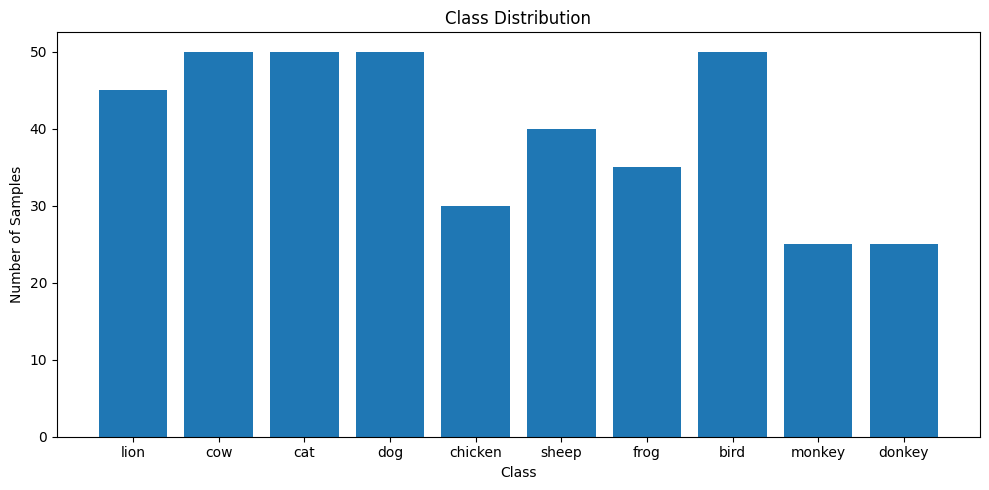

In [13]:
# CELL 11 — Exploratory Data Analysis: Class Distribution

import matplotlib.pyplot as plt
from collections import Counter

# Ambil semua label
labels = ds[split_name][label_column]

# Hitung frekuensi setiap kelas
label_counts = Counter(labels)

print("Jumlah kelas:", len(label_counts))
print("\nDistribusi kelas:")

for label, count in sorted(label_counts.items()):
    print(f"Class {label}: {count} samples")

# Plot distribusi kelas
plt.figure(figsize=(10, 5))

classes = list(label_counts.keys())
counts = list(label_counts.values())

plt.bar(classes, counts)

plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.title("Class Distribution")

plt.xticks(classes)
plt.tight_layout()
plt.show()

In [14]:
# CELL 12 — Inspect audio without automatic decoding

from datasets import Audio

# Matikan automatic audio decoding
ds = ds.cast_column(audio_column, Audio(decode=False))

# Ambil satu sample
sample = ds[split_name][0]

print("Audio column:", audio_column)
print("\nStruktur audio:")

audio_info = sample[audio_column]

print(type(audio_info))
print(audio_info)

Audio column: audio

Struktur audio:
<class 'dict'>
{'bytes': b'RIFF\xa4\x0f\x06\x00WAVEfmt \x10\x00\x00\x00\x01\x00\x02\x00"V\x00\x00\x88X\x01\x00\x04\x00\x10\x00data\x80\x0f\x06\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xfd\x00\x00\x00\xff\x00\xf0\xff#\xff\x00\x00\xff\x00f\x00\x10\x00\x00\x00\xff\x00f\x00\x10\x00\xb1\x00`\x01\xf0\xff#\xff\x00\x00\xff\x00\x00\x00\xfd\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00\x00\x00\xff\x00

In [15]:
# CELL 13 — Safe audio loader

import io
import numpy as np
import soundfile as sf

def load_audio_safe(sample, audio_column):
    """
    Membaca audio dari bytes atau path.
    Mengubah stereo menjadi mono.
    """

    audio_data = sample[audio_column]

    try:
        # Jika audio tersedia sebagai bytes
        if audio_data.get("bytes") is not None:
            y, sr = sf.read(io.BytesIO(audio_data["bytes"]))

        # Jika audio tersedia sebagai file path
        elif audio_data.get("path") is not None:
            y, sr = sf.read(audio_data["path"])

        else:
            raise ValueError("Audio tidak memiliki bytes maupun path.")

        # Convert ke float32
        y = np.asarray(y, dtype=np.float32)

        # Stereo → mono
        if y.ndim > 1:
            y = np.mean(y, axis=1)

        # Validasi
        if len(y) == 0:
            raise ValueError("Audio kosong.")

        if not np.isfinite(y).all():
            raise ValueError("Audio mengandung NaN atau Inf.")

        return y, int(sr)

    except Exception as e:
        raise RuntimeError(f"Gagal membaca audio: {e}")

In [16]:
# CELL 14 — Test audio loading

sample = ds[split_name][0]

y, sr = load_audio_safe(sample, audio_column)

print("Audio berhasil dibaca!")
print("Jumlah sample :", len(y))
print("Sampling rate :", sr, "Hz")
print("Durasi        :", round(len(y) / sr, 3), "detik")
print("Minimum       :", np.min(y))
print("Maximum       :", np.max(y))
print("Mean          :", np.mean(y))
print("Std           :", np.std(y))

Audio berhasil dibaca!
Jumlah sample : 99296
Sampling rate : 22050 Hz
Durasi        : 4.503 detik
Minimum       : -0.28677368
Maximum       : 0.28677368
Mean          : -3.1980206e-05
Std           : 0.06755283


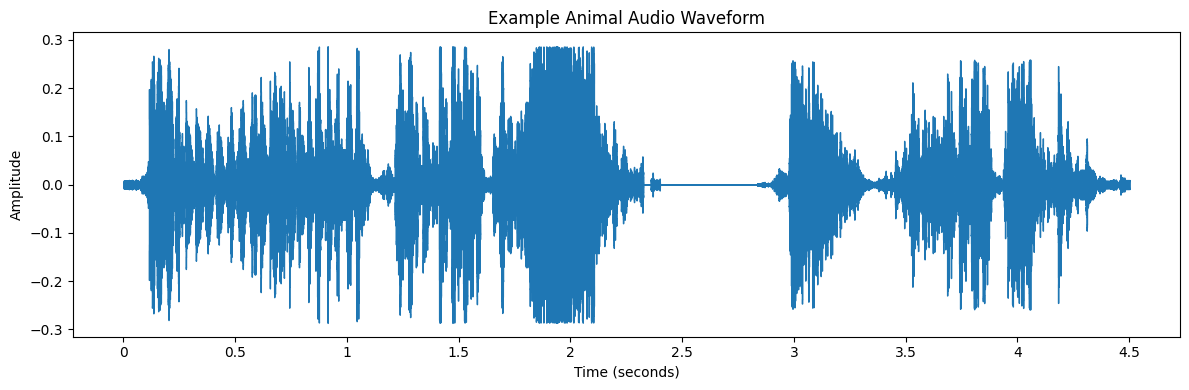

In [17]:
# CELL 15 — Plot waveform

plt.figure(figsize=(12, 4))

librosa.display.waveshow(y, sr=sr)

plt.title("Example Animal Audio Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

plt.tight_layout()
plt.show()

In [18]:
# CELL 16 — Analyze audio duration

durations = []
sampling_rates = []
valid_indices = []
failed_indices = []

for i in range(len(ds[split_name])):
    try:
        sample = ds[split_name][i]
        y_i, sr_i = load_audio_safe(sample, audio_column)

        duration = len(y_i) / sr_i

        durations.append(duration)
        sampling_rates.append(sr_i)
        valid_indices.append(i)

    except Exception as e:
        failed_indices.append((i, str(e)))

print("Total samples :", len(ds[split_name]))
print("Valid samples :", len(valid_indices))
print("Failed samples:", len(failed_indices))

print("\nDuration statistics:")
print("Minimum :", round(np.min(durations), 3), "seconds")
print("Maximum :", round(np.max(durations), 3), "seconds")
print("Mean    :", round(np.mean(durations), 3), "seconds")
print("Median  :", round(np.median(durations), 3), "seconds")

Total samples : 400
Valid samples : 400
Failed samples: 0

Duration statistics:
Minimum : 0.222 seconds
Maximum : 17.34 seconds
Mean    : 3.895 seconds
Median  : 2.365 seconds


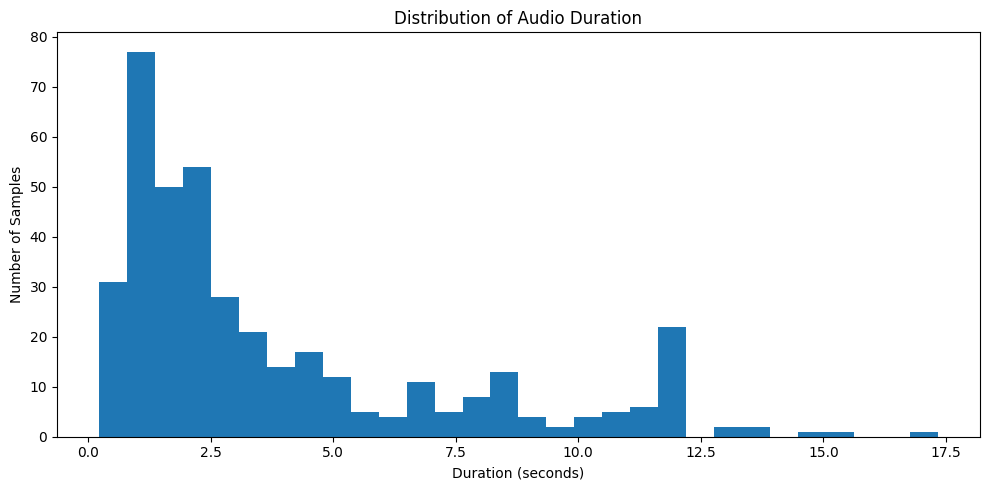

In [19]:
# CELL 17 — Duration distribution

plt.figure(figsize=(10, 5))

plt.hist(durations, bins=30)

plt.xlabel("Duration (seconds)")
plt.ylabel("Number of Samples")
plt.title("Distribution of Audio Duration")

plt.tight_layout()
plt.show()

Sampling rate distribution:
8000 Hz : 35 samples
8012 Hz : 1 samples
11000 Hz : 1 samples
11025 Hz : 123 samples
11127 Hz : 7 samples
16000 Hz : 104 samples
16393 Hz : 1 samples
20000 Hz : 1 samples
21276 Hz : 1 samples
22000 Hz : 4 samples
22050 Hz : 46 samples
22254 Hz : 1 samples
22255 Hz : 4 samples
24000 Hz : 2 samples
32000 Hz : 1 samples
44100 Hz : 67 samples
48000 Hz : 1 samples


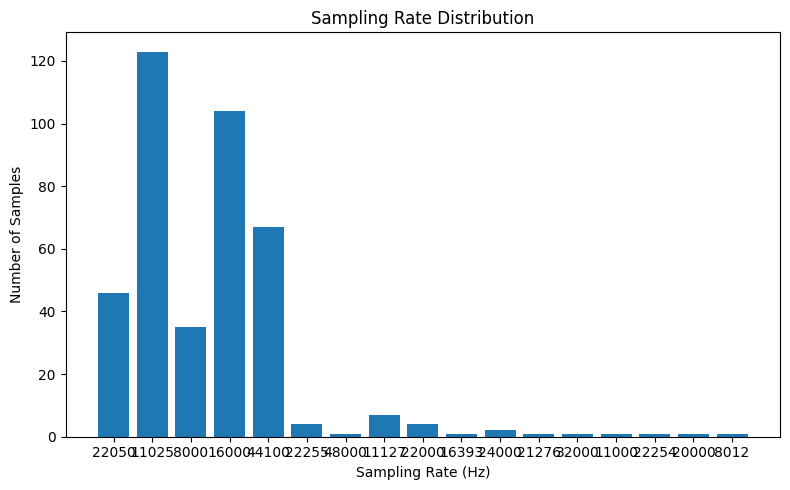

In [20]:
# CELL 18 — Sampling rate distribution

sr_counts = Counter(sampling_rates)

print("Sampling rate distribution:")

for sr_value, count in sorted(sr_counts.items()):
    print(f"{sr_value} Hz : {count} samples")

plt.figure(figsize=(8, 5))

plt.bar(
    [str(x) for x in sr_counts.keys()],
    sr_counts.values()
)

plt.xlabel("Sampling Rate (Hz)")
plt.ylabel("Number of Samples")
plt.title("Sampling Rate Distribution")

plt.tight_layout()
plt.show()

In [21]:
# CELL 19 — Set target sampling rate

TARGET_SR = 16000

print("Original sampling rates:")
for sr_value, count in sorted(sr_counts.items()):
    print(f"{sr_value} Hz : {count} samples")

print("\nTarget sampling rate:", TARGET_SR, "Hz")

Original sampling rates:
8000 Hz : 35 samples
8012 Hz : 1 samples
11000 Hz : 1 samples
11025 Hz : 123 samples
11127 Hz : 7 samples
16000 Hz : 104 samples
16393 Hz : 1 samples
20000 Hz : 1 samples
21276 Hz : 1 samples
22000 Hz : 4 samples
22050 Hz : 46 samples
22254 Hz : 1 samples
22255 Hz : 4 samples
24000 Hz : 2 samples
32000 Hz : 1 samples
44100 Hz : 67 samples
48000 Hz : 1 samples

Target sampling rate: 16000 Hz


In [22]:
# CELL 20 — Audio resampling function

def resample_audio(y, original_sr, target_sr=TARGET_SR):
    """
    Resample audio ke sampling rate target.
    """

    if original_sr == target_sr:
        return y.astype(np.float32)

    y_resampled = librosa.resample(
        y=y,
        orig_sr=original_sr,
        target_sr=target_sr
    )

    return y_resampled.astype(np.float32)

In [23]:
# CELL 21 — Test resampling

sample = ds[split_name][0]

y_original, sr_original = load_audio_safe(
    sample,
    audio_column
)

y_resampled = resample_audio(
    y_original,
    sr_original,
    TARGET_SR
)

print("Original")
print("Sampling rate :", sr_original)
print("Samples       :", len(y_original))
print("Duration      :", round(len(y_original) / sr_original, 3), "seconds")

print("\nAfter resampling")
print("Sampling rate :", TARGET_SR)
print("Samples       :", len(y_resampled))
print("Duration      :", round(len(y_resampled) / TARGET_SR, 3), "seconds")

Original
Sampling rate : 22050
Samples       : 99296
Duration      : 4.503 seconds

After resampling
Sampling rate : 16000
Samples       : 72052
Duration      : 4.503 seconds


In [28]:
# CELL 22 — Resample all audio samples

processed_audio = []
failed_audio = []

for i in range(len(ds[split_name])):
    try:
        sample = ds[split_name][i]

        # Load original audio
        y, sr = load_audio_safe(sample, audio_column)

        # Resample ke 16 kHz
        y_resampled = resample_audio(
            y,
            sr,
            TARGET_SR
        )

        processed_audio.append({
            "index": i,
            "audio": y_resampled,
            "sampling_rate": TARGET_SR,
            "original_sampling_rate": sr
        })

    except Exception as e:
        failed_audio.append({
            "index": i,
            "error": str(e)
        })

print("Total data       :", len(ds[split_name]))
print("Berhasil diproses:", len(processed_audio))
print("Gagal diproses   :", len(failed_audio))

Total data       : 400
Berhasil diproses: 400
Gagal diproses   : 0


In [29]:
# CELL 23 — Verify sampling rate after resampling

final_sampling_rates = [
    item["sampling_rate"]
    for item in processed_audio
]

print("Sampling rates setelah resampling:")
print(Counter(final_sampling_rates))

Sampling rates setelah resampling:
Counter({16000: 400})


In [30]:
# CELL 24 — Check duration after resampling

durations_after_resampling = []

for item in processed_audio:
    y = item["audio"]
    sr = item["sampling_rate"]

    duration = len(y) / sr
    durations_after_resampling.append(duration)

print("Duration after resampling:")
print("Minimum :", round(np.min(durations_after_resampling), 3), "seconds")
print("Maximum :", round(np.max(durations_after_resampling), 3), "seconds")
print("Mean    :", round(np.mean(durations_after_resampling), 3), "seconds")
print("Median  :", round(np.median(durations_after_resampling), 3), "seconds")

Duration after resampling:
Minimum : 0.222 seconds
Maximum : 17.34 seconds
Mean    : 3.895 seconds
Median  : 2.365 seconds


In [31]:
# CELL 25 — Normalize all resampled audio
# CELL 23 — Amplitude normalization

def normalize_audio(y):
    """
    Peak normalization ke rentang -1 sampai 1.
    """

    max_amplitude = np.max(np.abs(y))

    if max_amplitude == 0:
        return y.astype(np.float32)

    return (y / max_amplitude).astype(np.float32)

for item in processed_audio:
    item["audio"] = normalize_audio(item["audio"])

print("Normalization selesai untuk seluruh audio.")
print("Jumlah audio:", len(processed_audio))

Normalization selesai untuk seluruh audio.
Jumlah audio: 400


In [32]:
# CELL 26 — Verify normalization

np.random.seed(SEED)

check_indices = np.random.choice(
    len(processed_audio),
    size=min(5, len(processed_audio)),
    replace=False
)

for idx in check_indices:
    y = processed_audio[idx]["audio"]

    print(
        f"Audio {processed_audio[idx]['index']:4d} | "
        f"min = {np.min(y): .4f} | "
        f"max = {np.max(y): .4f} | "
        f"RMS = {np.sqrt(np.mean(y**2)): .4f}"
    )

Audio  209 | min = -1.0000 | max =  0.7514 | RMS =  0.1996
Audio  280 | min = -0.9929 | max =  1.0000 | RMS =  0.1060
Audio   33 | min = -1.0000 | max =  0.9415 | RMS =  0.2241
Audio  210 | min = -1.0000 | max =  0.7656 | RMS =  0.1674
Audio   93 | min = -0.8286 | max =  1.0000 | RMS =  0.1811


In [33]:
# CELL 27 — Create preprocessing metadata

metadata = []

for item in processed_audio:
    original_index = item["index"]

    metadata.append({
        "index": original_index,
        "label": ds[split_name][original_index][label_column],
        "original_sr": item["original_sampling_rate"],
        "processed_sr": item["sampling_rate"],
        "duration": len(item["audio"]) / TARGET_SR,
        "num_samples": len(item["audio"])
    })

metadata_df = pd.DataFrame(metadata)

print(metadata_df.head())
print("\nShape:", metadata_df.shape)

   index label  original_sr  processed_sr  duration  num_samples
0      0  lion        22050         16000  4.503250        72052
1      1  lion        11025         16000  1.170000        18720
2      2   cow        11025         16000  1.329562        21273
3      3   cow        22050         16000  4.574375        73190
4      4   cow        11025         16000  2.232750        35724

Shape: (400, 6)


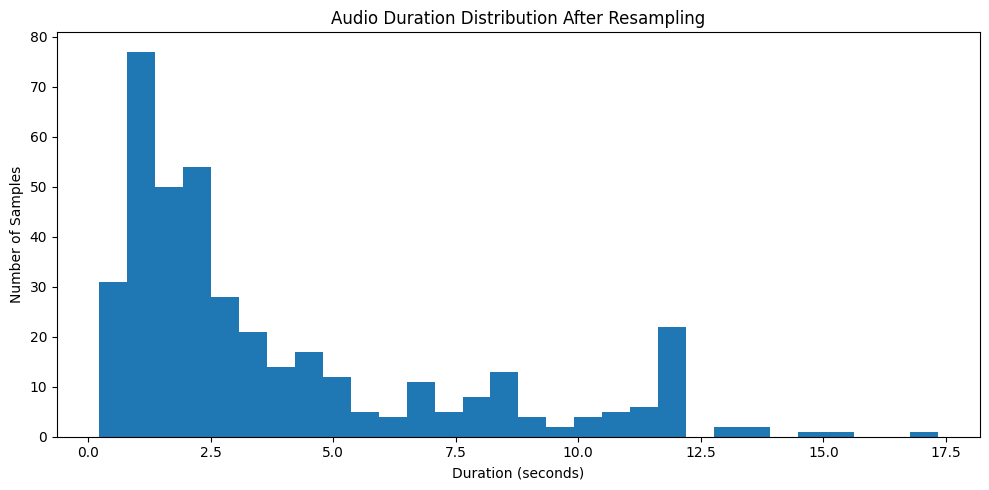

In [34]:
# CELL 28 — Duration distribution after preprocessing

plt.figure(figsize=(10, 5))

plt.hist(
    metadata_df["duration"],
    bins=30
)

plt.xlabel("Duration (seconds)")
plt.ylabel("Number of Samples")
plt.title("Audio Duration Distribution After Resampling")

plt.tight_layout()
plt.show()

In [37]:
# CELL 29 — Extract time-domain features from all audio

from scipy.stats import skew, kurtosis

def extract_time_domain_features(y):
    """
    Extract fitur domain waktu dari sinyal audio.
    """

    features = {}

    # Mean
    features["mean"] = np.mean(y)

    # Standard deviation
    features["std"] = np.std(y)

    # RMS
    features["rms"] = np.sqrt(np.mean(y ** 2))

    # Energy
    features["energy"] = np.sum(y ** 2)

    # Peak amplitude
    features["peak"] = np.max(np.abs(y))

    # Zero Crossing Rate
    features["zcr"] = np.mean(
        librosa.feature.zero_crossing_rate(y)[0]
    )

    # Crest factor
    if features["rms"] > 0:
        features["crest_factor"] = (
            features["peak"] / features["rms"]
        )
    else:
        features["crest_factor"] = 0

    # Skewness
    features["skewness"] = skew(y)

    # Kurtosis
    features["kurtosis"] = kurtosis(y)

    return features

time_domain_features = []

for item in processed_audio:

    y = item["audio"]

    features = extract_time_domain_features(y)

    # Tambahkan metadata
    features["index"] = item["index"]
    features["label"] = ds[split_name][item["index"]][label_column]
    features["duration"] = len(y) / TARGET_SR

    time_domain_features.append(features)

time_features_df = pd.DataFrame(time_domain_features)

print("Feature extraction selesai.")
print("Shape:", time_features_df.shape)

time_features_df.head()

Feature extraction selesai.
Shape: (400, 12)


,mean,std,rms,energy,peak,zcr,crest_factor,skewness,kurtosis,index,label,duration
0,-0.000103,0.212201,0.212201,3244.443359,1.0,0.116065,4.712517,0.047045,3.080204,0,lion,4.503250
1,-0.002592,0.201601,0.201618,760.965637,1.0,0.051929,4.959871,-0.212347,1.823685,1,lion,1.170000
2,-0.004283,0.354626,0.354652,2675.673584,1.0,0.104887,2.819667,-0.066005,-0.147992,2,cow,1.329562
3,-0.001377,0.242356,0.242360,4299.049316,1.0,0.205973,4.126099,0.172267,2.071285,3,cow,4.574375
4,-0.005921,0.266735,0.266801,2542.934570,1.0,0.166120,3.748111,-0.157644,1.886240,4,cow,2.232750


In [38]:
# CELL 30 — Statistical summary of time-domain features

feature_columns = [
    "mean",
    "std",
    "rms",
    "energy",
    "peak",
    "zcr",
    "crest_factor",
    "skewness",
    "kurtosis"
]

time_features_df[feature_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
mean,400.0,0.002457,0.019662,-0.050623,-0.003624,-0.000112,0.000055,0.173118
std,400.0,0.174495,0.082538,0.029890,0.105951,0.162868,0.230792,0.522856
rms,400.0,0.175788,0.082165,0.029902,0.106007,0.163981,0.230861,0.522889
energy,400.0,1691.371582,2206.709961,85.382195,464.593109,1077.904846,2237.573059,27639.576172
peak,400.0,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
zcr,400.0,0.180980,0.128943,0.020136,0.088600,0.141804,0.222140,0.536427
crest_factor,400.0,7.354213,4.426314,1.912453,4.331615,6.098282,9.433313,33.442436
skewness,400.0,-0.075760,1.278404,-24.817726,-0.136136,-0.025573,0.115740,1.085529
kurtosis,400.0,12.315557,40.362556,-1.275237,1.820629,4.336266,13.123531,769.961548


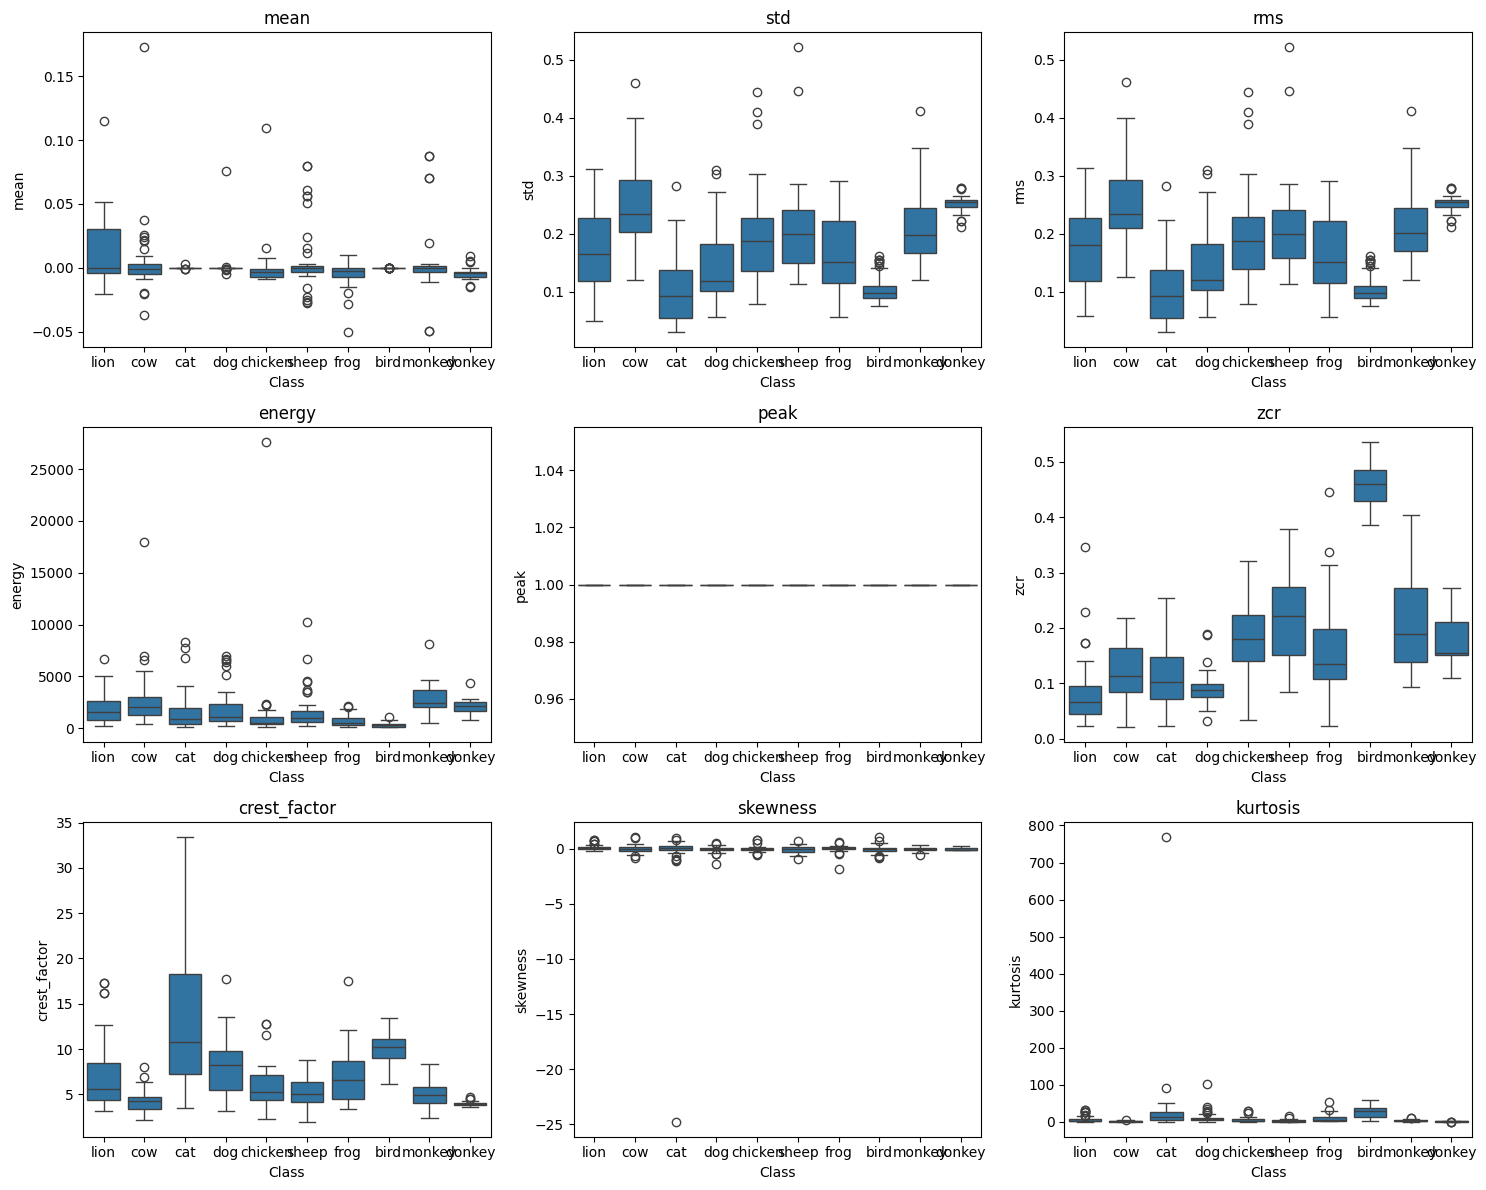

In [39]:
# CELL 31 — Time-domain features by class

fig, axes = plt.subplots(
    3, 3,
    figsize=(15, 12)
)

axes = axes.flatten()

for i, feature in enumerate(feature_columns):

    sns.boxplot(
        data=time_features_df,
        x="label",
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(feature)
    axes[i].set_xlabel("Class")
    axes[i].set_ylabel(feature)

plt.tight_layout()
plt.show()

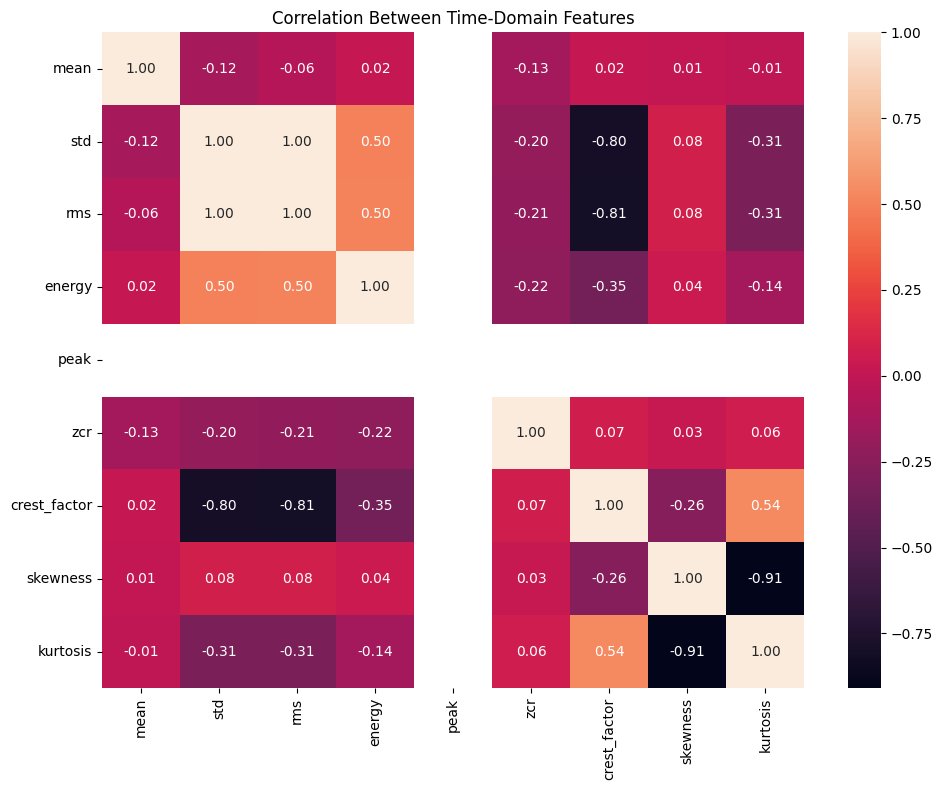

In [40]:
# CELL 32 — Feature correlation

plt.figure(figsize=(10, 8))

correlation_matrix = time_features_df[
    feature_columns
].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Between Time-Domain Features")

plt.tight_layout()
plt.show()

In [41]:
# CELL 33 — Fast Fourier Transform (FFT)

# Ambil audio pertama yang sudah dipreprocessing
y_fft = processed_audio[0]["audio"]

# Jumlah samples
N = len(y_fft)

# Sampling rate
sr_fft = TARGET_SR

# FFT
fft_result = np.fft.rfft(y_fft)

# Magnitude spectrum
magnitude = np.abs(fft_result)

# Frequency axis
frequencies = np.fft.rfftfreq(
    N,
    d=1 / sr_fft
)

print("Number of samples :", N)
print("Sampling rate     :", sr_fft, "Hz")
print("Frequency range   :", frequencies[0], "-", frequencies[-1], "Hz")

Number of samples : 72052
Sampling rate     : 16000 Hz
Frequency range   : 0.0 - 7999.999999999999 Hz


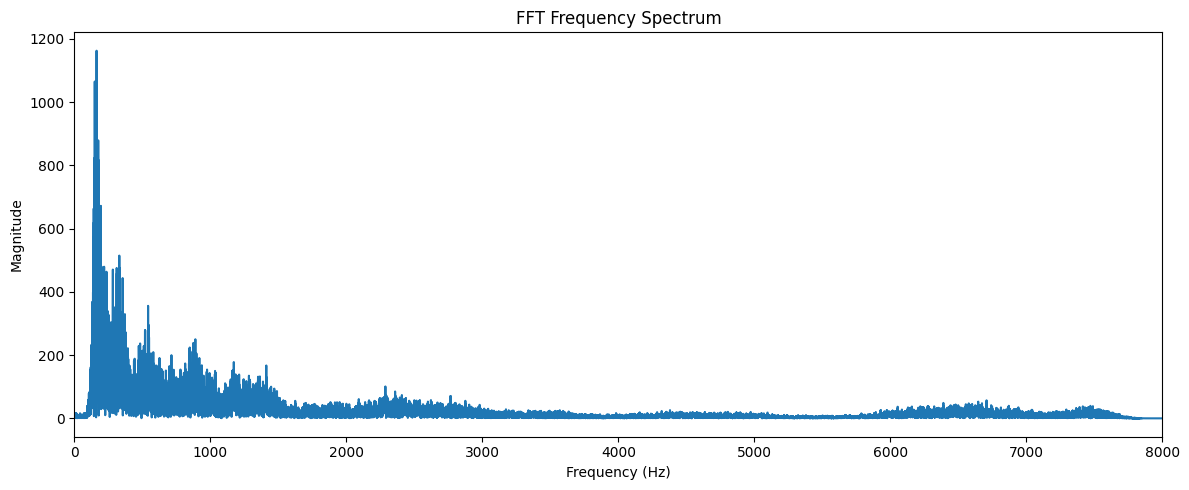

In [42]:
# CELL 34 — FFT spectrum visualization

plt.figure(figsize=(12, 5))

plt.plot(
    frequencies,
    magnitude
)

plt.xlabel("Frequency (Hz)")
plt.ylabel("Magnitude")
plt.title("FFT Frequency Spectrum")

plt.xlim(0, 8000)

plt.tight_layout()
plt.show()

In [43]:
# CELL 35 — Dominant frequency

# Abaikan DC component (0 Hz)
magnitude_no_dc = magnitude.copy()
magnitude_no_dc[0] = 0

dominant_index = np.argmax(magnitude_no_dc)

dominant_frequency = frequencies[dominant_index]

print("Dominant frequency:", round(dominant_frequency, 2), "Hz")

Dominant frequency: 162.99 Hz


In [44]:
# CELL 36 — Frequency-domain feature extraction

def extract_frequency_features(y, sr=TARGET_SR):

    features = {}

    # Spectral centroid
    features["spectral_centroid"] = np.mean(
        librosa.feature.spectral_centroid(
            y=y,
            sr=sr
        )[0]
    )

    # Spectral bandwidth
    features["spectral_bandwidth"] = np.mean(
        librosa.feature.spectral_bandwidth(
            y=y,
            sr=sr
        )[0]
    )

    # Spectral rolloff
    features["spectral_rolloff"] = np.mean(
        librosa.feature.spectral_rolloff(
            y=y,
            sr=sr
        )[0]
    )

    # Spectral flatness
    features["spectral_flatness"] = np.mean(
        librosa.feature.spectral_flatness(
            y=y
        )[0]
    )

    # Dominant frequency
    fft_result = np.fft.rfft(y)
    magnitude = np.abs(fft_result)
    frequencies = np.fft.rfftfreq(
        len(y),
        d=1 / sr
    )

    magnitude[0] = 0

    dominant_index = np.argmax(magnitude)

    features["dominant_frequency"] = frequencies[
        dominant_index
    ]

    return features

In [45]:
# CELL 37 — Test frequency-domain features

frequency_features = extract_frequency_features(
    processed_audio[0]["audio"],
    TARGET_SR
)

print("Frequency-domain features:")
print("-" * 45)

for name, value in frequency_features.items():
    print(f"{name:25s}: {value:.4f}")

Frequency-domain features:
---------------------------------------------
spectral_centroid        : 1744.9863
spectral_bandwidth       : 1965.8165
spectral_rolloff         : 3802.6928
spectral_flatness        : 0.0370
dominant_frequency       : 162.9934


In [46]:
# CELL 38 — Extract frequency-domain features from all audio

frequency_domain_features = []

for item in processed_audio:

    y = item["audio"]

    features = extract_frequency_features(
        y,
        TARGET_SR
    )

    # Tambahkan metadata
    features["index"] = item["index"]
    features["label"] = ds[split_name][item["index"]][label_column]
    features["duration"] = len(y) / TARGET_SR

    frequency_domain_features.append(features)

frequency_features_df = pd.DataFrame(
    frequency_domain_features
)

print("Frequency-domain feature extraction selesai.")
print("Shape:", frequency_features_df.shape)

frequency_features_df.head()

Frequency-domain feature extraction selesai.
Shape: (400, 8)


,spectral_centroid,spectral_bandwidth,spectral_rolloff,spectral_flatness,dominant_frequency,index,label,duration
0,1744.986283,1965.816541,3802.692819,0.037015,162.993394,0,lion,4.503250
1,836.631433,971.193050,1539.484797,0.000059,186.324786,1,lion,1.170000
2,1233.844026,903.167391,2175.223214,0.049542,497.156019,2,cow,1.329562
3,2089.947631,2080.864990,4966.455420,0.030758,313.922667,3,cow,4.574375
4,1833.592611,1227.559902,3208.147321,0.000366,821.856455,4,cow,2.232750


In [47]:
# CELL 39 — Statistical summary

frequency_feature_columns = [
    "dominant_frequency",
    "spectral_centroid",
    "spectral_bandwidth",
    "spectral_rolloff",
    "spectral_flatness"
]

frequency_features_df[
    frequency_feature_columns
].describe().T

,count,mean,std,min,25%,50%,75%,max
dominant_frequency,400.0,1334.361693,1545.073092,1.916627,283.502756,700.265786,1776.249392,6048.000000
spectral_centroid,400.0,1862.906016,1025.796802,436.776719,1168.661023,1532.359185,2102.723659,4473.175527
spectral_bandwidth,400.0,1261.609339,358.467150,467.051571,973.677359,1194.645909,1567.235409,2184.873411
spectral_rolloff,400.0,3069.366172,1420.965416,693.217330,2096.116624,2793.626494,3647.221812,6314.941406
spectral_flatness,400.0,0.024051,0.046170,0.000004,0.000257,0.005430,0.034046,0.490892


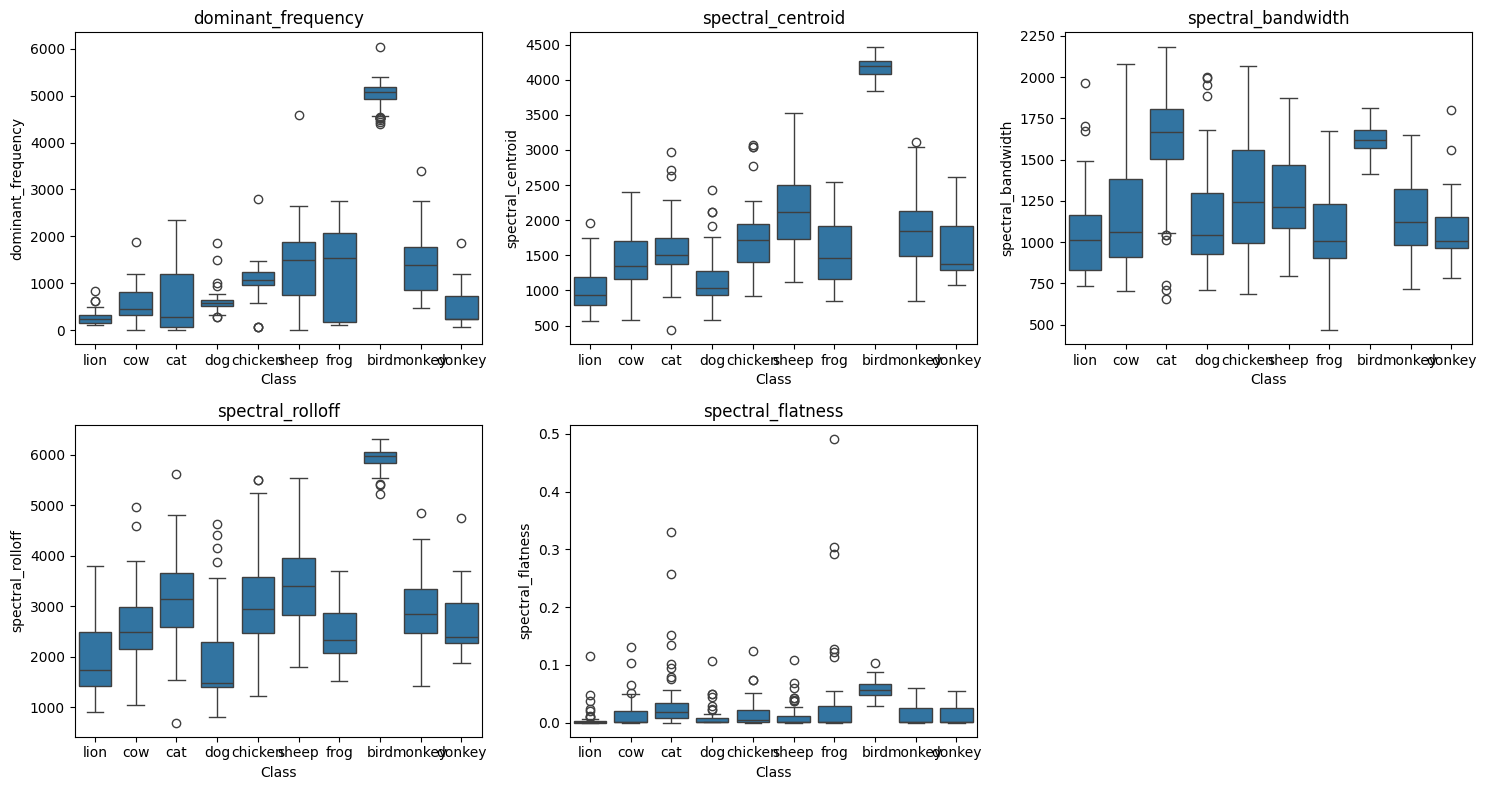

In [48]:
# CELL 40 — Frequency-domain features by class

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 8)
)

axes = axes.flatten()

for i, feature in enumerate(frequency_feature_columns):

    sns.boxplot(
        data=frequency_features_df,
        x="label",
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(feature)
    axes[i].set_xlabel("Class")
    axes[i].set_ylabel(feature)

# Matikan subplot yang tidak digunakan
for j in range(len(frequency_feature_columns), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

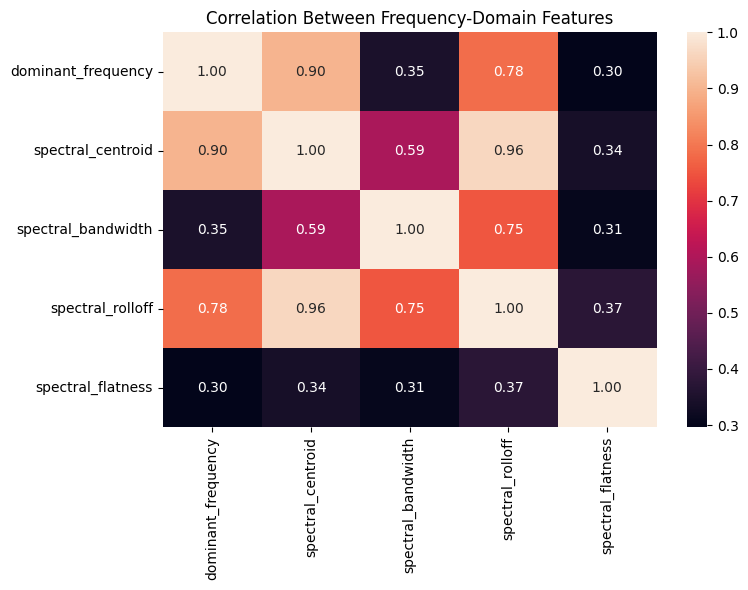

In [49]:
# CELL 41 — Frequency-domain feature correlation

plt.figure(figsize=(8, 6))

correlation_matrix = frequency_features_df[
    frequency_feature_columns
].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Between Frequency-Domain Features")

plt.tight_layout()
plt.show()

In [50]:
# CELL 42 — Short-Time Fourier Transform (STFT)

y_stft = processed_audio[0]["audio"]

# Parameter STFT
n_fft = 1024
hop_length = 256

# STFT
stft_result = librosa.stft(
    y_stft,
    n_fft=n_fft,
    hop_length=hop_length
)

# Magnitude spectrogram
stft_magnitude = np.abs(stft_result)

print("STFT shape:", stft_result.shape)
print("Frequency bins:", stft_magnitude.shape[0])
print("Time frames:", stft_magnitude.shape[1])

STFT shape: (513, 282)
Frequency bins: 513
Time frames: 282


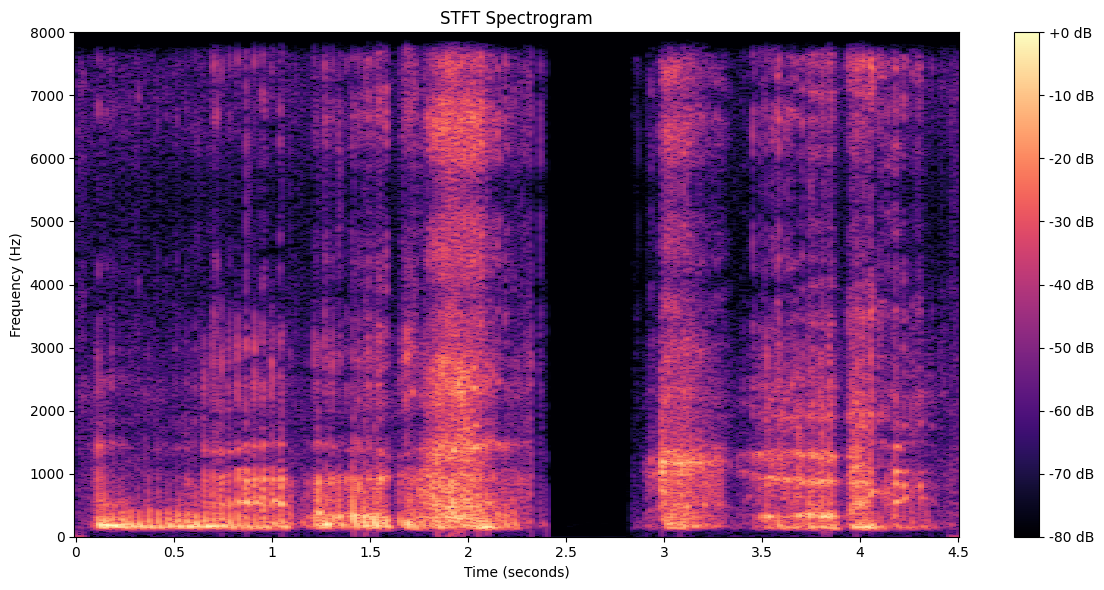

In [51]:
# CELL 43 — STFT Spectrogram

plt.figure(figsize=(12, 6))

librosa.display.specshow(
    librosa.amplitude_to_db(
        stft_magnitude,
        ref=np.max
    ),
    sr=TARGET_SR,
    hop_length=hop_length,
    x_axis="time",
    y_axis="hz"
)

plt.colorbar(format="%+2.0f dB")
plt.ylim(0, 8000)

plt.title("STFT Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()

In [52]:
# CELL 44 — Log-Magnitude Spectrogram

S_db = librosa.amplitude_to_db(
    stft_magnitude,
    ref=np.max
)

print("Minimum dB:", S_db.min())
print("Maximum dB:", S_db.max())
print("Shape:", S_db.shape)

Minimum dB: -80.0
Maximum dB: 0.0
Shape: (513, 282)


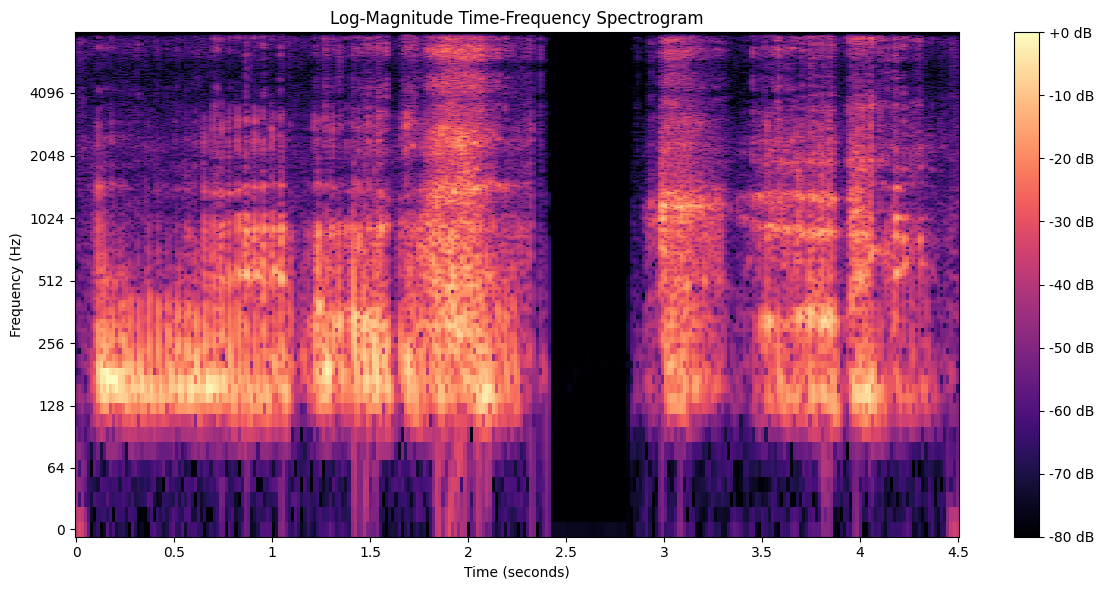

In [53]:
# CELL 45 — Time-Frequency Spectrogram

plt.figure(figsize=(12, 6))

librosa.display.specshow(
    S_db,
    sr=TARGET_SR,
    hop_length=hop_length,
    x_axis="time",
    y_axis="log"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Log-Magnitude Time-Frequency Spectrogram")

plt.xlabel("Time (seconds)")
plt.ylabel("Frequency (Hz)")

plt.tight_layout()
plt.show()

In [54]:
# CELL 46 — Mel-Spectrogram

y_mel = processed_audio[0]["audio"]

n_mels = 128

mel_spectrogram = librosa.feature.melspectrogram(
    y=y_mel,
    sr=TARGET_SR,
    n_fft=n_fft,
    hop_length=hop_length,
    n_mels=n_mels,
    fmin=0,
    fmax=TARGET_SR // 2
)

mel_db = librosa.power_to_db(
    mel_spectrogram,
    ref=np.max
)

print("Mel-Spectrogram shape:", mel_db.shape)
print("Number of Mel bins:", n_mels)

Mel-Spectrogram shape: (128, 282)
Number of Mel bins: 128


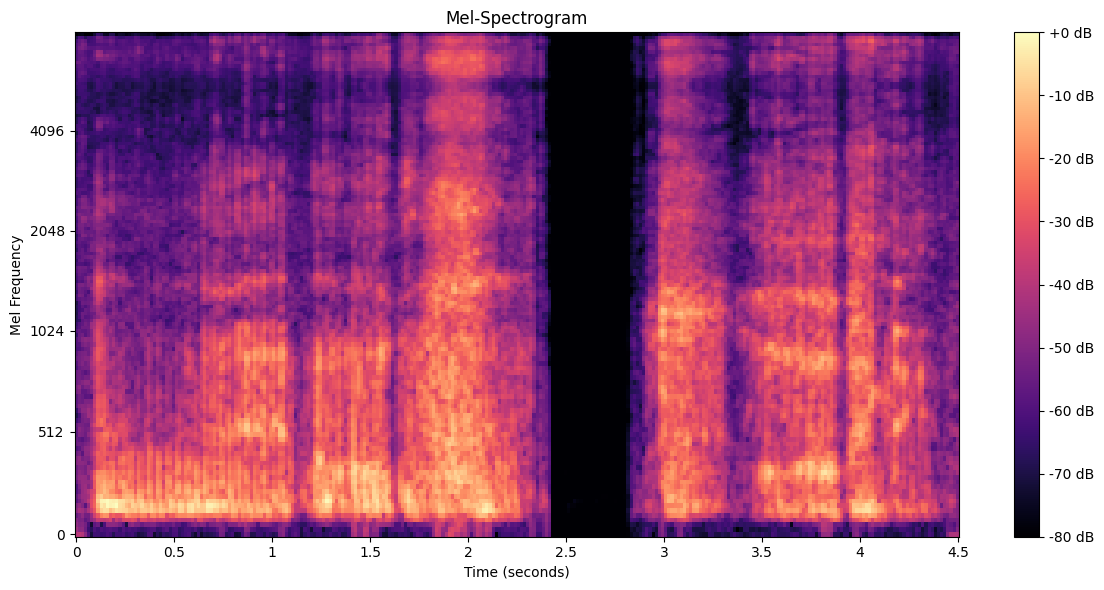

In [55]:
# CELL 47 — Visualize Mel-Spectrogram

plt.figure(figsize=(12, 6))

librosa.display.specshow(
    mel_db,
    sr=TARGET_SR,
    hop_length=hop_length,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")

plt.title("Mel-Spectrogram")
plt.xlabel("Time (seconds)")
plt.ylabel("Mel Frequency")

plt.tight_layout()
plt.show()

In [56]:
# CELL 48 — Mel-Spectrogram statistical features

mel_features = {
    "mel_mean": np.mean(mel_db),
    "mel_std": np.std(mel_db),
    "mel_min": np.min(mel_db),
    "mel_max": np.max(mel_db)
}

print("Mel-Spectrogram statistics:")

for name, value in mel_features.items():
    print(f"{name:12s}: {value:.4f}")

Mel-Spectrogram statistics:
mel_mean    : -48.2060
mel_std     : 17.1968
mel_min     : -80.0000
mel_max     : 0.0000


In [57]:
# CELL 49 — MFCC extraction

n_mfcc = 13

mfcc = librosa.feature.mfcc(
    y=y_mel,
    sr=TARGET_SR,
    n_mfcc=n_mfcc,
    n_fft=n_fft,
    hop_length=hop_length,
    n_mels=n_mels
)

print("MFCC shape:", mfcc.shape)
print("Number of MFCC coefficients:", n_mfcc)

MFCC shape: (13, 282)
Number of MFCC coefficients: 13


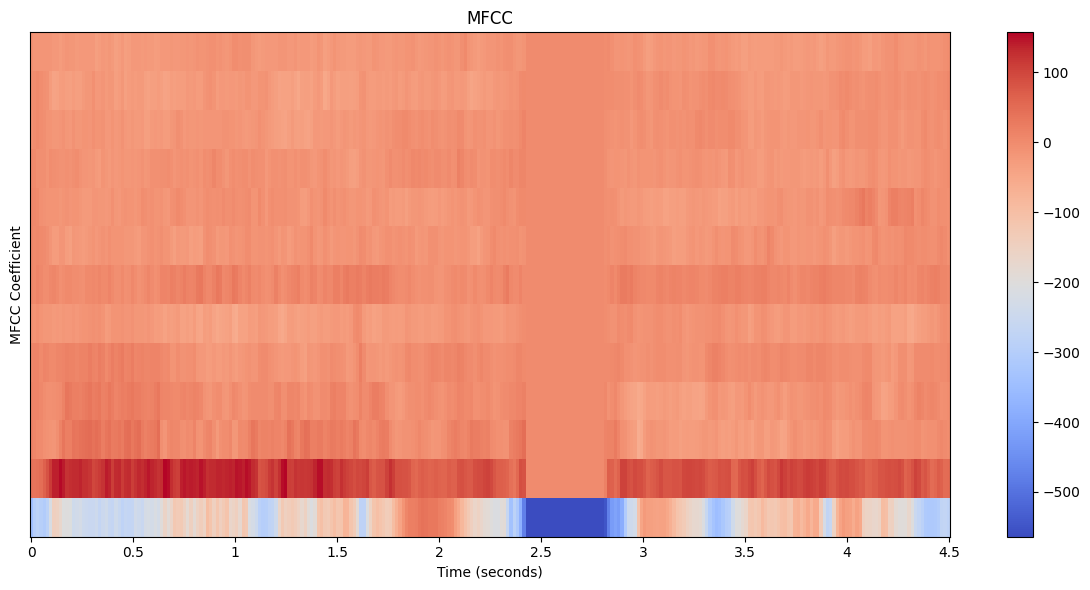

In [58]:
# CELL 50 — MFCC visualization

plt.figure(figsize=(12, 6))

librosa.display.specshow(
    mfcc,
    sr=TARGET_SR,
    hop_length=hop_length,
    x_axis="time"
)

plt.colorbar()

plt.title("MFCC")
plt.xlabel("Time (seconds)")
plt.ylabel("MFCC Coefficient")

plt.tight_layout()
plt.show()

In [59]:
# CELL 51 — Extract Mel-Spectrogram and MFCC features for all audio

mel_mfcc_features = []

for item in processed_audio:

    y = item["audio"]

    # =========================
    # Mel-Spectrogram
    # =========================

    mel = librosa.feature.melspectrogram(
        y=y,
        sr=TARGET_SR,
        n_fft=n_fft,
        hop_length=hop_length,
        n_mels=n_mels,
        fmin=0,
        fmax=TARGET_SR // 2
    )

    mel_db = librosa.power_to_db(
        mel,
        ref=np.max
    )

    # =========================
    # MFCC
    # =========================

    mfcc = librosa.feature.mfcc(
        y=y,
        sr=TARGET_SR,
        n_mfcc=n_mfcc,
        n_fft=n_fft,
        hop_length=hop_length,
        n_mels=n_mels
    )

    # =========================
    # Statistical aggregation
    # =========================

    features = {
        "index": item["index"],
        "label": ds[split_name][item["index"]][label_column],
    }

    # Mel statistics
    features["mel_mean"] = np.mean(mel_db)
    features["mel_std"] = np.std(mel_db)

    # MFCC mean dan std
    for i in range(n_mfcc):
        features[f"mfcc_{i+1}_mean"] = np.mean(mfcc[i])
        features[f"mfcc_{i+1}_std"] = np.std(mfcc[i])

    mel_mfcc_features.append(features)

mel_mfcc_df = pd.DataFrame(mel_mfcc_features)

print("Mel-Spectrogram + MFCC extraction selesai.")
print("Shape:", mel_mfcc_df.shape)

mel_mfcc_df.head()

Mel-Spectrogram + MFCC extraction selesai.
Shape: (400, 30)


,index,label,mel_mean,mel_std,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,...,mfcc_9_mean,mfcc_9_std,mfcc_10_mean,mfcc_10_std,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std
0,0,lion,-48.205963,17.196754,-204.339310,146.967331,89.806755,38.315979,0.752176,21.414320,...,-11.712614,12.138197,-10.593848,8.965788,-12.381205,9.579537,-17.293015,12.633995,-17.251389,8.596125
1,1,lion,-42.400169,19.179922,-209.283371,39.368801,185.245911,15.504855,-37.533344,13.962485,...,-7.297622,7.687008,-13.681430,7.900850,6.978103,6.506491,-14.800343,5.966041,20.444794,5.206408
2,2,cow,-49.663383,21.336102,-214.810623,131.797913,141.119812,53.665970,-88.955803,40.444584,...,-15.258789,9.986506,-7.345204,19.335899,6.262888,9.756232,-3.614607,11.311016,17.090866,14.799376
3,3,cow,-51.421482,13.560411,-243.856369,106.102539,43.903061,26.224968,-6.979653,11.673530,...,-14.789756,8.562854,-16.907795,10.864097,-9.706318,7.431563,1.518797,6.194632,-14.657613,8.778023
4,4,cow,-43.685108,17.951382,-160.364563,78.184471,108.615906,34.776554,-90.744667,28.243685,...,21.547354,14.598944,3.315878,16.187038,4.721896,12.016418,-24.412844,10.902812,-0.719031,7.429605


In [60]:
# CELL 52 — MFCC statistical summary

mfcc_feature_columns = [
    col
    for col in mel_mfcc_df.columns
    if col.startswith("mfcc_")
]

print("Jumlah MFCC-derived features:", len(mfcc_feature_columns))

mel_mfcc_df[mfcc_feature_columns].describe().T

Jumlah MFCC-derived features: 26


,count,mean,std,min,25%,50%,75%,max
mfcc_1_mean,400.0,-279.546051,98.267982,-500.277008,-347.141151,-268.906403,-203.253830,-65.848175
mfcc_1_std,400.0,87.130928,37.771812,18.490566,60.674462,79.760521,110.337513,262.440430
mfcc_2_mean,400.0,79.781853,88.433929,-152.225281,55.959579,103.577381,144.884331,201.737167
mfcc_2_std,400.0,32.286270,16.888332,5.380939,19.679036,28.173115,41.058514,103.073380
mfcc_3_mean,400.0,-57.850861,41.972965,-186.781494,-85.173552,-57.529440,-27.594718,44.381630
mfcc_3_std,400.0,28.626352,14.188142,5.077885,18.347037,27.330702,35.283430,81.873566
mfcc_4_mean,400.0,13.287295,31.497519,-96.117210,-12.274780,13.960480,34.480713,111.801155
mfcc_4_std,400.0,16.228033,6.645866,5.446178,11.684603,15.043990,19.822514,48.854393
mfcc_5_mean,400.0,-15.007404,19.767408,-96.347588,-26.954189,-12.112891,-2.841970,26.377373
mfcc_5_std,400.0,13.790069,5.666185,4.619422,9.626272,12.885984,16.152014,41.255455


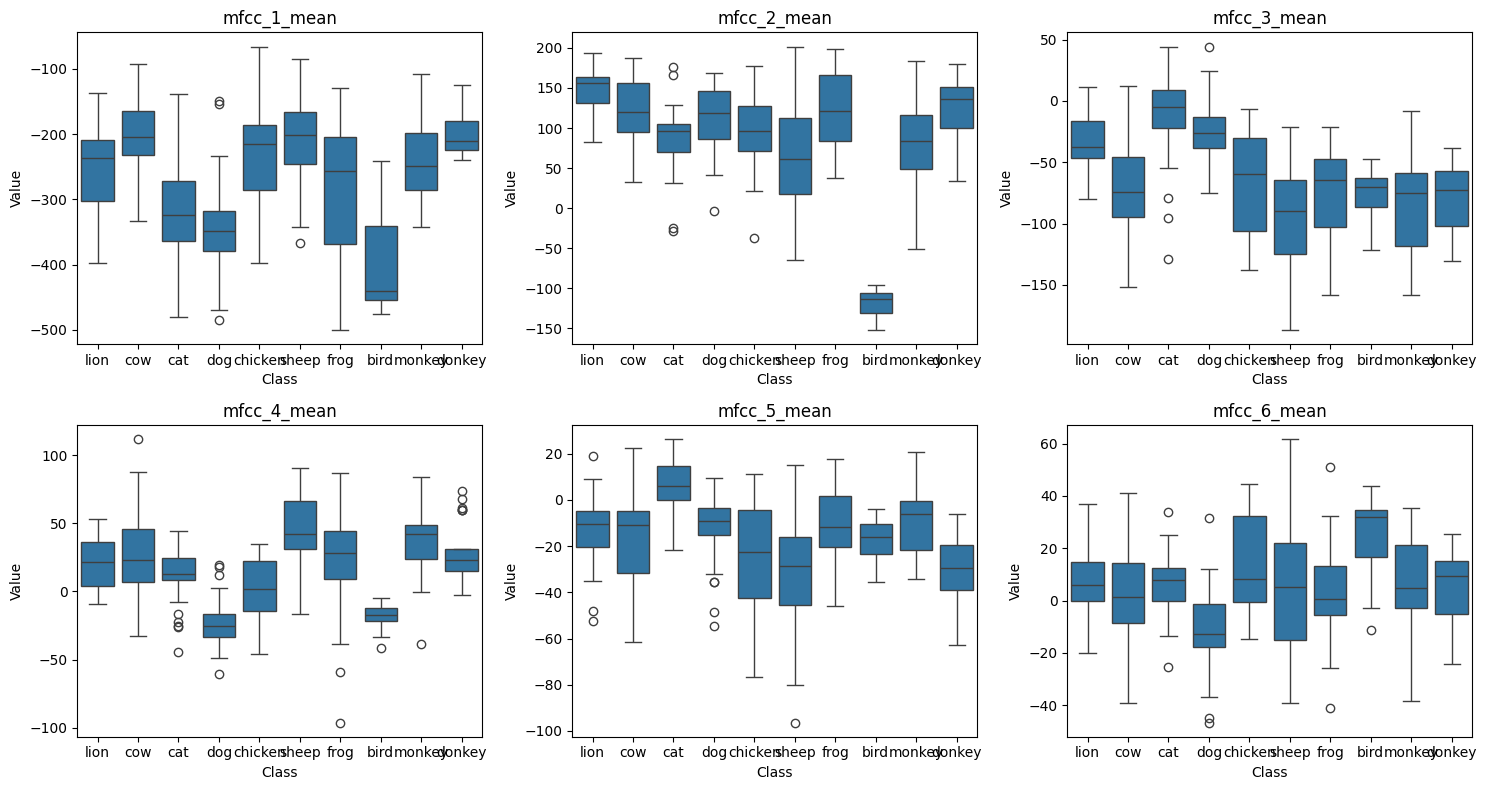

In [61]:
# CELL 53 — MFCC features by class

selected_mfcc = [
    "mfcc_1_mean",
    "mfcc_2_mean",
    "mfcc_3_mean",
    "mfcc_4_mean",
    "mfcc_5_mean",
    "mfcc_6_mean"
]

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 8)
)

axes = axes.flatten()

for i, feature in enumerate(selected_mfcc):

    sns.boxplot(
        data=mel_mfcc_df,
        x="label",
        y=feature,
        ax=axes[i]
    )

    axes[i].set_title(feature)
    axes[i].set_xlabel("Class")
    axes[i].set_ylabel("Value")

plt.tight_layout()
plt.show()

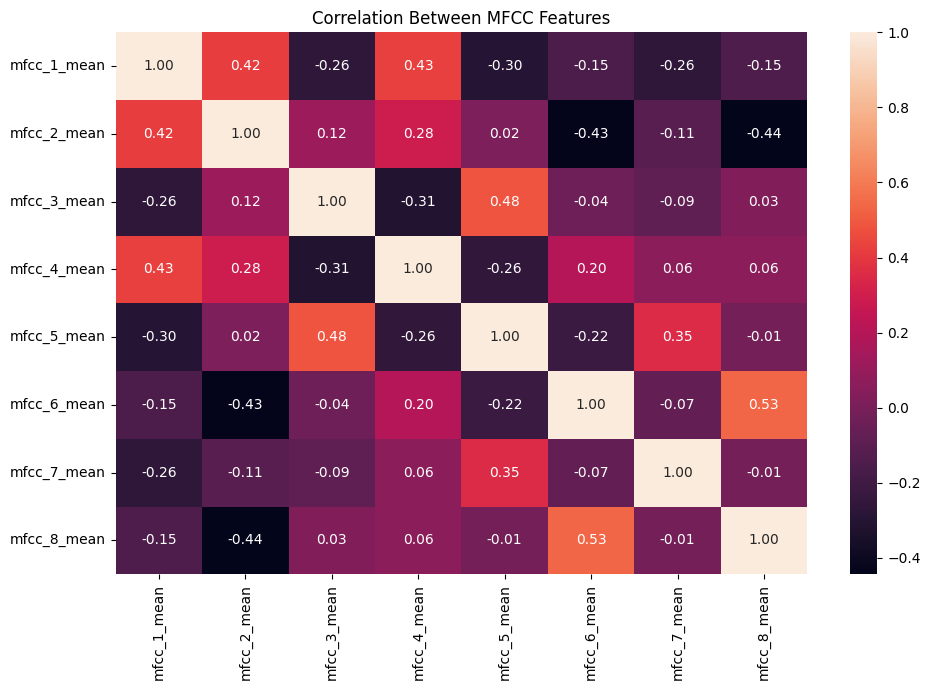

In [62]:
# CELL 54 — MFCC correlation

selected_mfcc_corr = [
    "mfcc_1_mean",
    "mfcc_2_mean",
    "mfcc_3_mean",
    "mfcc_4_mean",
    "mfcc_5_mean",
    "mfcc_6_mean",
    "mfcc_7_mean",
    "mfcc_8_mean"
]

plt.figure(figsize=(10, 7))

corr = mel_mfcc_df[selected_mfcc_corr].corr()

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Between MFCC Features")

plt.tight_layout()
plt.show()

In [63]:
# CELL 55 — Combine all extracted features

# Gabungkan berdasarkan index
feature_df = (
    time_features_df
    .merge(
        frequency_features_df,
        on=["index", "label", "duration"],
        how="inner"
    )
    .merge(
        mel_mfcc_df,
        on=["index", "label"],
        how="inner"
    )
)

print("Combined feature matrix shape:", feature_df.shape)

feature_df.head()

Combined feature matrix shape: (400, 45)


,mean,std,rms,energy,peak,zcr,crest_factor,skewness,kurtosis,index,...,mfcc_9_mean,mfcc_9_std,mfcc_10_mean,mfcc_10_std,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,mfcc_13_mean,mfcc_13_std
0,-0.000103,0.212201,0.212201,3244.443359,1.0,0.116065,4.712517,0.047045,3.080204,0,...,-11.712614,12.138197,-10.593848,8.965788,-12.381205,9.579537,-17.293015,12.633995,-17.251389,8.596125
1,-0.002592,0.201601,0.201618,760.965637,1.0,0.051929,4.959871,-0.212347,1.823685,1,...,-7.297622,7.687008,-13.681430,7.900850,6.978103,6.506491,-14.800343,5.966041,20.444794,5.206408
2,-0.004283,0.354626,0.354652,2675.673584,1.0,0.104887,2.819667,-0.066005,-0.147992,2,...,-15.258789,9.986506,-7.345204,19.335899,6.262888,9.756232,-3.614607,11.311016,17.090866,14.799376
3,-0.001377,0.242356,0.242360,4299.049316,1.0,0.205973,4.126099,0.172267,2.071285,3,...,-14.789756,8.562854,-16.907795,10.864097,-9.706318,7.431563,1.518797,6.194632,-14.657613,8.778023
4,-0.005921,0.266735,0.266801,2542.934570,1.0,0.166120,3.748111,-0.157644,1.886240,4,...,21.547354,14.598944,3.315878,16.187038,4.721896,12.016418,-24.412844,10.902812,-0.719031,7.429605


In [64]:
# CELL 56 — Separate features and labels

# Kolom yang bukan fitur
metadata_columns = [
    "index",
    "label",
    "duration"
]

feature_columns_all = [
    col
    for col in feature_df.columns
    if col not in metadata_columns
]

X = feature_df[feature_columns_all].copy()
y = feature_df["label"].copy()

print("Jumlah samples :", len(X))
print("Jumlah features:", X.shape[1])

print("\nFeature groups:")
print("Time-domain       :", len(feature_columns))
print("Frequency-domain  :", len(frequency_feature_columns))
print("MFCC-derived      :", len(mfcc_feature_columns))

Jumlah samples : 400
Jumlah features: 42

Feature groups:
Time-domain       : 9
Frequency-domain  : 5
MFCC-derived      : 26


In [65]:
# CELL 57 — Train / Validation / Test split
# Target: 70% train, 10% validation, 20% test

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=SEED,
    stratify=y
)

# Dari 30% temporary:
# 1/3 = 10% total → validation
# 2/3 = 20% total → test

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=2/3,
    random_state=SEED,
    stratify=y_temp
)

print("Train      :", len(X_train), f"({len(X_train)/len(X)*100:.1f}%)")
print("Validation :", len(X_val), f"({len(X_val)/len(X)*100:.1f}%)")
print("Test       :", len(X_test), f"({len(X_test)/len(X)*100:.1f}%)")

Train      : 280 (70.0%)
Validation : 40 (10.0%)
Test       : 80 (20.0%)


In [66]:
# CELL 58 — Check class distribution in each split

print("TRAIN:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nVALIDATION:")
print(y_val.value_counts(normalize=True).sort_index())

print("\nTEST:")
print(y_test.value_counts(normalize=True).sort_index())

TRAIN:
label
bird       0.125000
cat        0.125000
chicken    0.075000
cow        0.125000
dog        0.125000
donkey     0.060714
frog       0.089286
lion       0.110714
monkey     0.064286
sheep      0.100000
Name: proportion, dtype: float64

VALIDATION:
label
bird       0.125
cat        0.125
chicken    0.075
cow        0.125
dog        0.125
donkey     0.075
frog       0.075
lion       0.125
monkey     0.050
sheep      0.100
Name: proportion, dtype: float64

TEST:
label
bird       0.1250
cat        0.1250
chicken    0.0750
cow        0.1250
dog        0.1250
donkey     0.0625
frog       0.0875
lion       0.1125
monkey     0.0625
sheep      0.1000
Name: proportion, dtype: float64


In [67]:
# CELL 59 — Standardize features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)

print("Train shape :", X_train_scaled.shape)
print("Val shape   :", X_val_scaled.shape)
print("Test shape  :", X_test_scaled.shape)

Train shape : (280, 42)
Val shape   : (40, 42)
Test shape  : (80, 42)


In [68]:
# CELL 60 — PCA feature analysis

from sklearn.decomposition import PCA

pca = PCA(
    n_components=2,
    random_state=SEED
)

X_train_pca = pca.fit_transform(X_train_scaled)

print("Explained variance ratio:")
print("PC1:", round(pca.explained_variance_ratio_[0], 4))
print("PC2:", round(pca.explained_variance_ratio_[1], 4))

print(
    "Total:",
    round(
        pca.explained_variance_ratio_.sum(),
        4
    )
)

Explained variance ratio:
PC1: 0.1872
PC2: 0.1395
Total: 0.3267


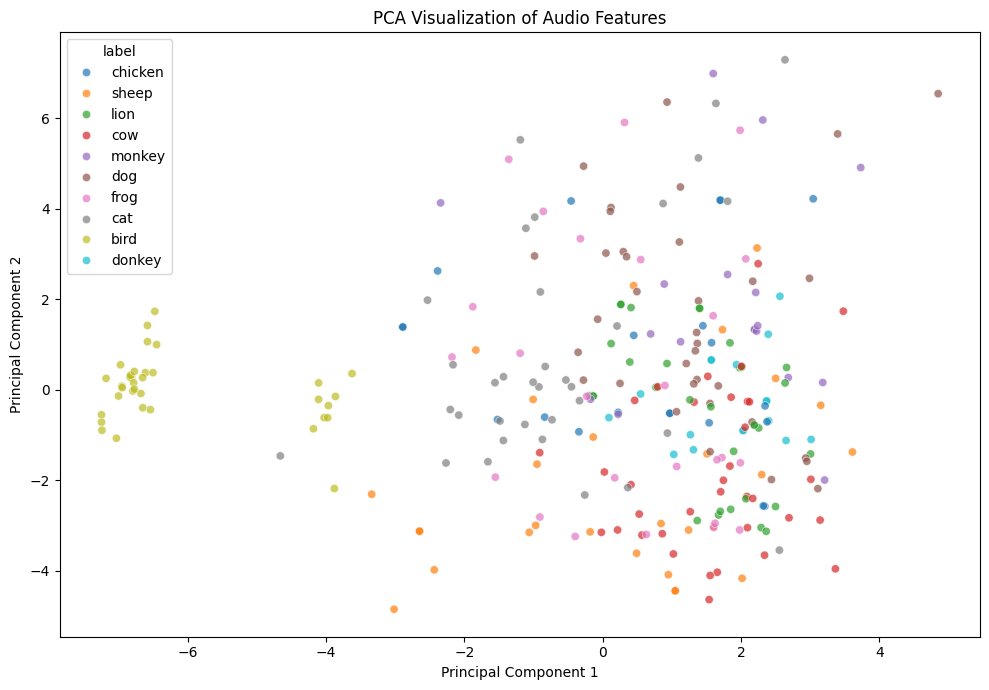

In [69]:
# CELL 61 — PCA visualization

pca_df = pd.DataFrame({
    "PC1": X_train_pca[:, 0],
    "PC2": X_train_pca[:, 1],
    "label": y_train.values
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="label",
    palette="tab10",
    alpha=0.7
)

plt.title("PCA Visualization of Audio Features")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

In [70]:
# CELL 62 — Define fixed input length for 1D CNN

CLIP_DURATION = 3.0  # seconds
TARGET_LENGTH = int(CLIP_DURATION * TARGET_SR)

print("Target sampling rate :", TARGET_SR, "Hz")
print("Target duration      :", CLIP_DURATION, "seconds")
print("Target length        :", TARGET_LENGTH, "samples")

Target sampling rate : 16000 Hz
Target duration      : 3.0 seconds
Target length        : 48000 samples


In [71]:
# CELL 63 — Pad or crop audio

def pad_or_crop_audio(y, target_length=TARGET_LENGTH):
    """
    Membuat panjang audio menjadi target_length.
    Audio panjang -> crop
    Audio pendek -> zero padding
    """

    current_length = len(y)

    # Jika terlalu panjang → crop
    if current_length > target_length:

        y_fixed = y[:target_length]

    # Jika terlalu pendek → zero padding
    elif current_length < target_length:

        padding_length = target_length - current_length

        y_fixed = np.pad(
            y,
            (0, padding_length),
            mode="constant"
        )

    # Jika sudah sesuai
    else:
        y_fixed = y

    return y_fixed.astype(np.float32)

In [72]:
# CELL 64 — Create fixed-length audio dataset

cnn_audio = []
cnn_labels = []
cnn_indices = []

for item in processed_audio:

    y = item["audio"]

    # Fix audio length
    y_fixed = pad_or_crop_audio(y)

    # Simpan
    cnn_audio.append(y_fixed)

    original_index = item["index"]

    cnn_labels.append(
        ds[split_name][original_index][label_column]
    )

    cnn_indices.append(original_index)

cnn_audio = np.array(cnn_audio, dtype=np.float32)
cnn_labels = np.array(cnn_labels)
cnn_indices = np.array(cnn_indices)

print("CNN audio shape :", cnn_audio.shape)
print("Labels shape    :", cnn_labels.shape)

CNN audio shape : (400, 48000)
Labels shape    : (400,)


In [73]:
# CELL 65 — Verify fixed-length audio

lengths = [
    len(audio)
    for audio in cnn_audio
]

print("Unique lengths:", np.unique(lengths))
print("Expected length:", TARGET_LENGTH)

Unique lengths: [48000]
Expected length: 48000


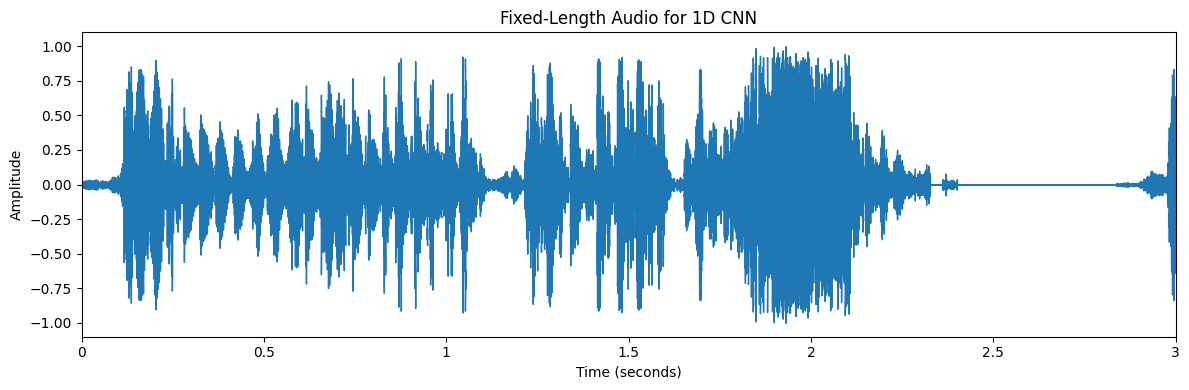

In [74]:
# CELL 66 — Visualize fixed-length waveform

plt.figure(figsize=(12, 4))

librosa.display.waveshow(
    cnn_audio[0],
    sr=TARGET_SR
)

plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Fixed-Length Audio for 1D CNN")

plt.xlim(0, CLIP_DURATION)

plt.tight_layout()
plt.show()

In [75]:
# CELL 67 — Train / Validation / Test split for waveform data

# First split: 70% train, 30% temporary
train_idx, temp_idx = train_test_split(
    np.arange(len(cnn_audio)),
    test_size=0.30,
    random_state=SEED,
    stratify=cnn_labels
)

# Second split:
# 30% temporary -> 10% validation + 20% test
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=2/3,
    random_state=SEED,
    stratify=cnn_labels[temp_idx]
)

print("Train      :", len(train_idx), f"({len(train_idx)/len(cnn_audio)*100:.1f}%)")
print("Validation :", len(val_idx), f"({len(val_idx)/len(cnn_audio)*100:.1f}%)")
print("Test       :", len(test_idx), f"({len(test_idx)/len(cnn_audio)*100:.1f}%)")

Train      : 280 (70.0%)
Validation : 40 (10.0%)
Test       : 80 (20.0%)


In [76]:
# CELL 68 — Create CNN train/validation/test sets

X_cnn_train = cnn_audio[train_idx]
X_cnn_val = cnn_audio[val_idx]
X_cnn_test = cnn_audio[test_idx]

y_cnn_train = cnn_labels[train_idx]
y_cnn_val = cnn_labels[val_idx]
y_cnn_test = cnn_labels[test_idx]

print("Train:")
print("  X:", X_cnn_train.shape)
print("  y:", y_cnn_train.shape)

print("\nValidation:")
print("  X:", X_cnn_val.shape)
print("  y:", y_cnn_val.shape)

print("\nTest:")
print("  X:", X_cnn_test.shape)
print("  y:", y_cnn_test.shape)

Train:
  X: (280, 48000)
  y: (280,)

Validation:
  X: (40, 48000)
  y: (40,)

Test:
  X: (80, 48000)
  y: (80,)


In [77]:
# CELL 69 — Verify class distribution

def show_class_distribution(labels, name):
    counts = Counter(labels)

    print(f"\n{name}")
    print("-" * 30)

    total = len(labels)

    for label, count in sorted(counts.items()):
        percentage = count / total * 100
        print(
            f"Class {label}: "
            f"{count} samples "
            f"({percentage:.2f}%)"
        )

show_class_distribution(y_cnn_train, "TRAIN")
show_class_distribution(y_cnn_val, "VALIDATION")
show_class_distribution(y_cnn_test, "TEST")


TRAIN
------------------------------
Class bird: 35 samples (12.50%)
Class cat: 35 samples (12.50%)
Class chicken: 21 samples (7.50%)
Class cow: 35 samples (12.50%)
Class dog: 35 samples (12.50%)
Class donkey: 17 samples (6.07%)
Class frog: 25 samples (8.93%)
Class lion: 31 samples (11.07%)
Class monkey: 18 samples (6.43%)
Class sheep: 28 samples (10.00%)

VALIDATION
------------------------------
Class bird: 5 samples (12.50%)
Class cat: 5 samples (12.50%)
Class chicken: 3 samples (7.50%)
Class cow: 5 samples (12.50%)
Class dog: 5 samples (12.50%)
Class donkey: 3 samples (7.50%)
Class frog: 3 samples (7.50%)
Class lion: 5 samples (12.50%)
Class monkey: 2 samples (5.00%)
Class sheep: 4 samples (10.00%)

TEST
------------------------------
Class bird: 10 samples (12.50%)
Class cat: 10 samples (12.50%)
Class chicken: 6 samples (7.50%)
Class cow: 10 samples (12.50%)
Class dog: 10 samples (12.50%)
Class donkey: 5 samples (6.25%)
Class frog: 7 samples (8.75%)
Class lion: 9 samples (11.25%)

In [78]:
# CELL 70 — Encode labels for CNN

label_encoder = LabelEncoder()

y_cnn_train_encoded = label_encoder.fit_transform(
    y_cnn_train
)

y_cnn_val_encoded = label_encoder.transform(
    y_cnn_val
)

y_cnn_test_encoded = label_encoder.transform(
    y_cnn_test
)

print("Classes:")
for i, class_name in enumerate(label_encoder.classes_):
    print(f"{i}: {class_name}")

Classes:
0: bird
1: cat
2: chicken
3: cow
4: dog
5: donkey
6: frog
7: lion
8: monkey
9: sheep


In [79]:
# CELL 71 — Number of classes

NUM_CLASSES = len(label_encoder.classes_)

print("Number of classes:", NUM_CLASSES)

Number of classes: 10


In [80]:
# CELL 72 — Import PyTorch

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader

print("PyTorch version:", torch.__version__)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

PyTorch version: 2.11.0+cpu
Device: cpu


In [81]:
# CELL 73 — Custom PyTorch Dataset

class AnimalAudioDataset(Dataset):

    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):

        # Audio waveform
        audio = torch.tensor(
            self.X[idx],
            dtype=torch.float32
        )

        # Tambahkan channel dimension
        # [48000] → [1, 48000]
        audio = audio.unsqueeze(0)

        # Label
        label = torch.tensor(
            self.y[idx],
            dtype=torch.long
        )

        return audio, label

In [82]:
# CELL 74 — Create PyTorch datasets

train_dataset = AnimalAudioDataset(
    X_cnn_train,
    y_cnn_train_encoded
)

val_dataset = AnimalAudioDataset(
    X_cnn_val,
    y_cnn_val_encoded
)

test_dataset = AnimalAudioDataset(
    X_cnn_test,
    y_cnn_test_encoded
)

print("Train dataset:", len(train_dataset))
print("Val dataset  :", len(val_dataset))
print("Test dataset :", len(test_dataset))

Train dataset: 280
Val dataset  : 40
Test dataset : 80


In [83]:
# CELL 75 — Create DataLoaders

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))
print("Test batches :", len(test_loader))

Train batches: 18
Val batches  : 3
Test batches : 5


In [84]:
# CELL 76 — Check batch shape

audio_batch, label_batch = next(iter(train_loader))

print("Audio batch shape :", audio_batch.shape)
print("Label batch shape :", label_batch.shape)

print("\nExpected audio format:")
print("(batch_size, channels, sequence_length)")

print("\nActual:")
print(audio_batch.shape)

Audio batch shape : torch.Size([16, 1, 48000])
Label batch shape : torch.Size([16])

Expected audio format:
(batch_size, channels, sequence_length)

Actual:
torch.Size([16, 1, 48000])


In [85]:
# CELL 77 — 1D CNN model

class AnimalAudioCNN(nn.Module):

    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(

            # Block 1
            nn.Conv1d(
                in_channels=1,
                out_channels=32,
                kernel_size=9,
                stride=2,
                padding=4
            ),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            # Block 2
            nn.Conv1d(
                in_channels=32,
                out_channels=64,
                kernel_size=7,
                stride=2,
                padding=3
            ),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            # Block 3
            nn.Conv1d(
                in_channels=64,
                out_channels=128,
                kernel_size=5,
                stride=2,
                padding=2
            ),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.MaxPool1d(kernel_size=2),

            # Block 4
            nn.Conv1d(
                in_channels=128,
                out_channels=256,
                kernel_size=3,
                stride=2,
                padding=1
            ),
            nn.BatchNorm1d(256),
            nn.ReLU(),

            # Global average pooling
            nn.AdaptiveAvgPool1d(1)
        )

        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Dropout(0.3),

            nn.Linear(
                256,
                num_classes
            )
        )

    def forward(self, x):

        x = self.features(x)

        x = self.classifier(x)

        return x

In [86]:
# CELL 78 — Initialize model

model = AnimalAudioCNN(
    num_classes=NUM_CLASSES
)

model = model.to(device)

print(model)

AnimalAudioCNN(
  (features): Sequential(
    (0): Conv1d(1, 32, kernel_size=(9,), stride=(2,), padding=(4,))
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv1d(32, 64, kernel_size=(7,), stride=(2,), padding=(3,))
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv1d(64, 128, kernel_size=(5,), stride=(2,), padding=(2,))
    (9): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Conv1d(128, 256, kernel_size=(3,), stride=(2,), padding=(1,))
    (13): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (14): ReLU()
 

In [87]:
# CELL 79 — Test forward pass

model.eval()

with torch.no_grad():

    test_output = model(
        audio_batch.to(device)
    )

print("Input shape :", audio_batch.shape)
print("Output shape:", test_output.shape)

Input shape : torch.Size([16, 1, 48000])
Output shape: torch.Size([16, 10])


In [88]:
# CELL 80 — Count trainable parameters

total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    f"Trainable parameters: "
    f"{total_params:,}"
)

Trainable parameters: 157,898


In [89]:
# CELL 81 — Loss function and optimizer

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

print("Loss     :", criterion)
print("Optimizer:", optimizer)

Loss     : CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0001
)


In [90]:
# CELL 82 — Training configuration

NUM_EPOCHS = 50
PATIENCE = 8

best_val_loss = float("inf")
patience_counter = 0

history = {
    "train_loss": [],
    "val_loss": [],
    "train_accuracy": [],
    "val_accuracy": []
}

print("Epochs :", NUM_EPOCHS)
print("Early stopping patience :", PATIENCE)

Epochs : 50
Early stopping patience : 8


In [91]:
# CELL 83 — Training loop

for epoch in range(NUM_EPOCHS):

    # ==================================================
    # TRAINING
    # ==================================================

    model.train()

    running_train_loss = 0.0
    train_correct = 0
    train_total = 0

    for audio, labels in train_loader:

        audio = audio.to(device)
        labels = labels.to(device)

        # Reset gradients
        optimizer.zero_grad()

        # Forward
        outputs = model(audio)

        # Loss
        loss = criterion(outputs, labels)

        # Backward
        loss.backward()

        # Update weights
        optimizer.step()

        # Statistics
        running_train_loss += (
            loss.item() * audio.size(0)
        )

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        train_correct += (
            predictions == labels
        ).sum().item()

        train_total += labels.size(0)

    train_loss = (
        running_train_loss / train_total
    )

    train_accuracy = (
        train_correct / train_total
    )

    # ==================================================
    # VALIDATION
    # ==================================================

    model.eval()

    running_val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for audio, labels in val_loader:

            audio = audio.to(device)
            labels = labels.to(device)

            outputs = model(audio)

            loss = criterion(
                outputs,
                labels
            )

            running_val_loss += (
                loss.item() * audio.size(0)
            )

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            val_correct += (
                predictions == labels
            ).sum().item()

            val_total += labels.size(0)

    val_loss = (
        running_val_loss / val_total
    )

    val_accuracy = (
        val_correct / val_total
    )

    # ==================================================
    # SAVE HISTORY
    # ==================================================

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    history["train_accuracy"].append(
        train_accuracy
    )

    history["val_accuracy"].append(
        val_accuracy
    )

    # ==================================================
    # PRINT RESULTS
    # ==================================================

    print(
        f"Epoch [{epoch+1:02d}/{NUM_EPOCHS}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_accuracy:.4f} "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_accuracy:.4f}"
    )

    # ==================================================
    # EARLY STOPPING
    # ==================================================

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            model.state_dict(),
            "best_animal_audio_cnn.pth"
        )

    else:

        patience_counter += 1

        if patience_counter >= PATIENCE:

            print(
                f"\nEarly stopping at epoch {epoch+1}"
            )

            break

Epoch [01/50] | Train Loss: 2.0537 | Train Acc: 0.2357 | Val Loss: 2.2938 | Val Acc: 0.1250
Epoch [02/50] | Train Loss: 1.7252 | Train Acc: 0.4214 | Val Loss: 2.1039 | Val Acc: 0.2750
Epoch [03/50] | Train Loss: 1.5451 | Train Acc: 0.5143 | Val Loss: 1.7488 | Val Acc: 0.3250
Epoch [04/50] | Train Loss: 1.3991 | Train Acc: 0.5714 | Val Loss: 1.6045 | Val Acc: 0.4750
Epoch [05/50] | Train Loss: 1.3633 | Train Acc: 0.6071 | Val Loss: 1.4167 | Val Acc: 0.6000
Epoch [06/50] | Train Loss: 1.3099 | Train Acc: 0.6000 | Val Loss: 1.3966 | Val Acc: 0.6000
Epoch [07/50] | Train Loss: 1.2595 | Train Acc: 0.6250 | Val Loss: 1.3634 | Val Acc: 0.5500
Epoch [08/50] | Train Loss: 1.1742 | Train Acc: 0.6750 | Val Loss: 1.3001 | Val Acc: 0.6000
Epoch [09/50] | Train Loss: 1.1269 | Train Acc: 0.6750 | Val Loss: 1.2656 | Val Acc: 0.6250
Epoch [10/50] | Train Loss: 1.0752 | Train Acc: 0.7000 | Val Loss: 1.2339 | Val Acc: 0.6250
Epoch [11/50] | Train Loss: 1.0380 | Train Acc: 0.7000 | Val Loss: 1.0458 | Val 

In [92]:
# CELL 84 — Load best model

model.load_state_dict(
    torch.load(
        "best_animal_audio_cnn.pth",
        map_location=device
    )
)

model.eval()

print("Best model loaded successfully.")
print("Best validation loss:", best_val_loss)

Best model loaded successfully.
Best validation loss: 0.6626173317432403


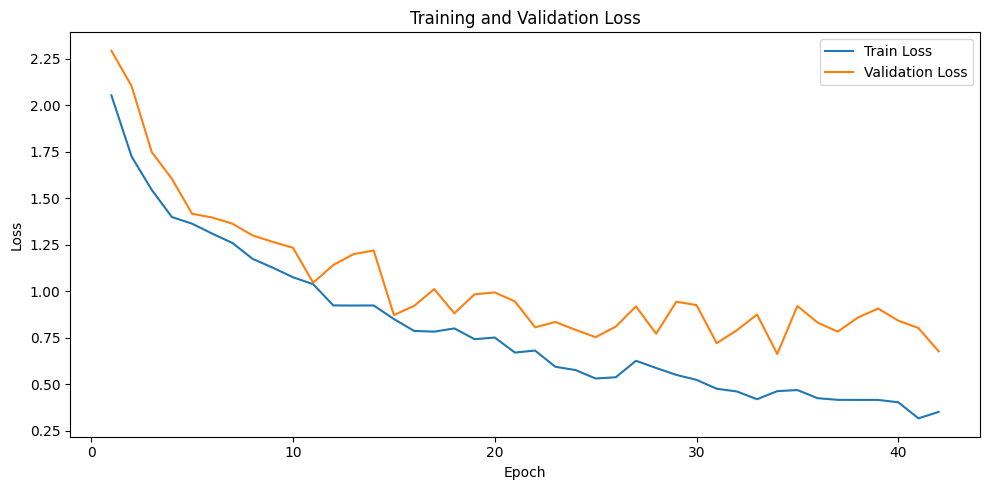

In [93]:
# CELL 85 — Training and validation curves

epochs = range(
    1,
    len(history["train_loss"]) + 1
)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    history["train_loss"],
    label="Train Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.tight_layout()
plt.show()

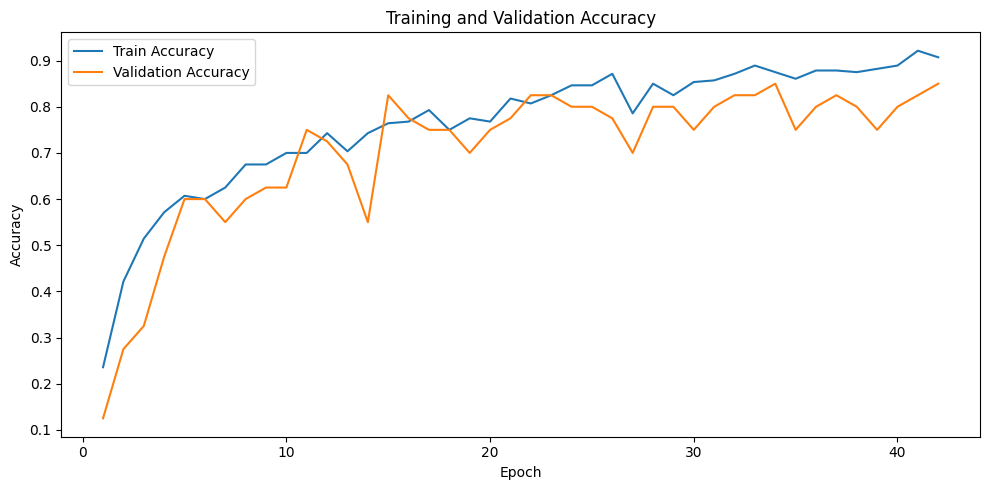

In [94]:
# CELL 86 — Accuracy curves

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    history["train_accuracy"],
    label="Train Accuracy"
)

plt.plot(
    epochs,
    history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.tight_layout()
plt.show()

In [95]:
# CELL 87 — Final prediction on test set

model.eval()

all_test_labels = []
all_test_predictions = []
all_test_probabilities = []

with torch.no_grad():

    for audio, labels in test_loader:

        audio = audio.to(device)

        outputs = model(audio)

        # Probability
        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        # Predicted class
        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        all_test_labels.extend(
            labels.numpy()
        )

        all_test_predictions.extend(
            predictions.cpu().numpy()
        )

        all_test_probabilities.extend(
            probabilities.cpu().numpy()
        )

y_true = np.array(all_test_labels)
y_pred = np.array(all_test_predictions)
y_prob = np.array(all_test_probabilities)

print("Test samples:", len(y_true))
print("Probability shape:", y_prob.shape)

Test samples: 80
Probability shape: (80, 10)


In [96]:
# CELL 88 — Classification metrics

test_accuracy = accuracy_score(
    y_true,
    y_pred
)

test_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print("Final Test Performance")
print("=" * 40)

print(f"Accuracy  : {test_accuracy:.4f}")
print(f"Precision : {test_precision:.4f}")
print(f"Recall    : {test_recall:.4f}")
print(f"Macro F1  : {test_f1:.4f}")

Final Test Performance
Accuracy  : 0.8125
Precision : 0.8311
Recall    : 0.8294
Macro F1  : 0.8137


In [97]:
# CELL 89 — Detailed classification report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=[
            str(c)
            for c in label_encoder.classes_
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

        bird       1.00      1.00      1.00        10
         cat       0.62      0.50      0.56        10
     chicken       0.56      0.83      0.67         6
         cow       1.00      0.70      0.82        10
         dog       0.89      0.80      0.84        10
      donkey       1.00      1.00      1.00         5
        frog       1.00      0.57      0.73         7
        lion       0.73      0.89      0.80         9
      monkey       0.71      1.00      0.83         5
       sheep       0.80      1.00      0.89         8

    accuracy                           0.81        80
   macro avg       0.83      0.83      0.81        80
weighted avg       0.84      0.81      0.81        80



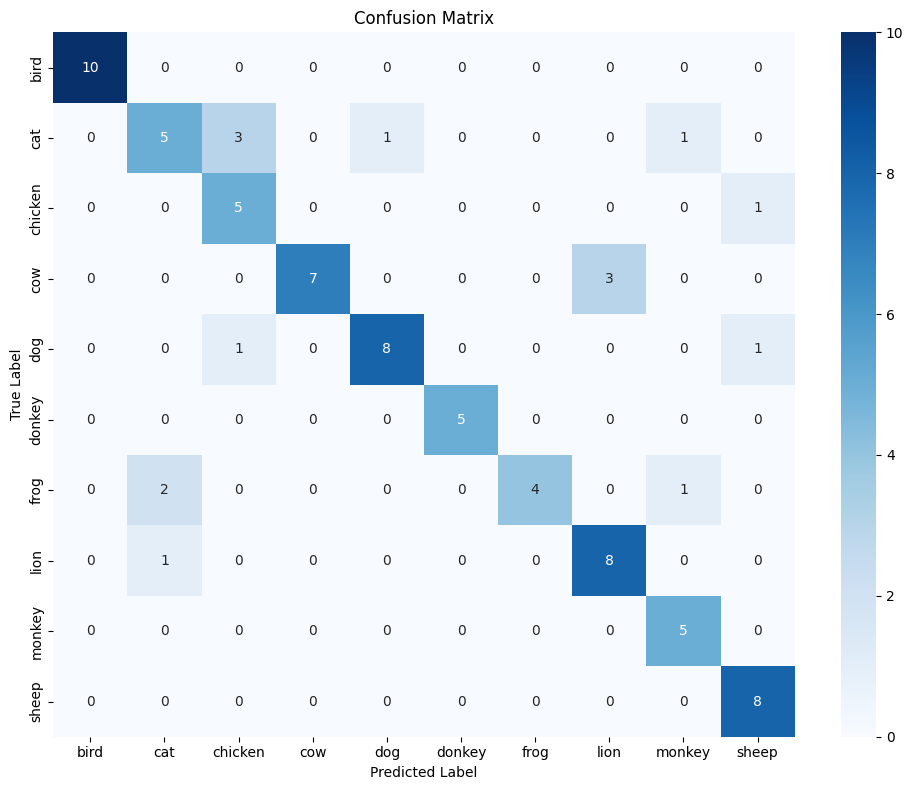

In [98]:
# CELL 90 — Confusion matrix

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")

plt.tight_layout()
plt.show()

In [99]:
# CELL 91 — Multiclass ROC-AUC

try:

    test_roc_auc = roc_auc_score(
        y_true,
        y_prob,
        multi_class="ovr",
        average="macro"
    )

    print(
        f"Macro ROC-AUC (OvR): "
        f"{test_roc_auc:.4f}"
    )

except ValueError as e:

    print("ROC-AUC tidak dapat dihitung:")
    print(e)

Macro ROC-AUC (OvR): 0.9720


In [100]:
# CELL 92 — Final evaluation summary

results = {
    "Accuracy": test_accuracy,
    "Macro Precision": test_precision,
    "Macro Recall": test_recall,
    "Macro F1": test_f1
}

if "test_roc_auc" in globals():
    results["Macro ROC-AUC"] = test_roc_auc

results_df = pd.DataFrame(
    results.items(),
    columns=["Metric", "Score"]
)

results_df

,Metric,Score
0,Accuracy,0.812500
1,Macro Precision,0.831100
2,Macro Recall,0.829365
3,Macro F1,0.813735
4,Macro ROC-AUC,0.971996


In [101]:
# CELL 93 — Model size and parameters

import os

# Simpan model FP32
fp32_model_path = "animal_audio_cnn_fp32.pth"

torch.save(
    model.state_dict(),
    fp32_model_path
)

# Jumlah parameter
total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

# File size
model_size_mb = (
    os.path.getsize(fp32_model_path)
    / (1024 ** 2)
)

print("Model Complexity")
print("=" * 40)

print(
    f"Total parameters     : {total_params:,}"
)

print(
    f"Trainable parameters : {trainable_params:,}"
)

print(
    f"FP32 model size      : {model_size_mb:.2f} MB"
)

Model Complexity
Total parameters     : 157,898
Trainable parameters : 157,898
FP32 model size      : 0.62 MB


In [102]:
# CELL 94 — Install THOP

%pip install -q thop

In [103]:
# CELL 95 — Calculate MACs and FLOPs

from thop import profile

# Contoh input sesuai bentuk CNN
dummy_input = torch.randn(
    1,
    1,
    TARGET_LENGTH
).to(device)

model.eval()

macs, params = profile(
    model,
    inputs=(dummy_input,),
    verbose=False
)

flops = 2 * macs

print("Computational Complexity")
print("=" * 40)

print(f"MACs  : {macs:,.0f}")
print(f"FLOPs : {flops:,.0f}")
print(f"Params: {params:,.0f}")

print("\nReadable:")
print(f"MACs  : {macs / 1e6:.2f} M")
print(f"FLOPs : {flops / 1e6:.2f} M")

Computational Complexity
MACs  : 197,090,816
FLOPs : 394,181,632
Params: 157,898

Readable:
MACs  : 197.09 M
FLOPs : 394.18 M


In [104]:
# CELL 96 — Inference time

import time

model.eval()

# Ambil satu batch
audio_batch, labels_batch = next(iter(test_loader))

audio_batch = audio_batch.to(device)

# Warm-up
with torch.no_grad():
    for _ in range(10):
        _ = model(audio_batch)

if device.type == "cuda":
    torch.cuda.synchronize()

# Timing
start_time = time.perf_counter()

with torch.no_grad():
    _ = model(audio_batch)

if device.type == "cuda":
    torch.cuda.synchronize()

end_time = time.perf_counter()

elapsed_time = end_time - start_time

print("Inference time")
print("=" * 40)

print(
    f"Batch size        : {audio_batch.size(0)}"
)

print(
    f"Batch inference   : {elapsed_time * 1000:.3f} ms"
)

print(
    f"Per-sample        : "
    f"{elapsed_time / audio_batch.size(0) * 1000:.3f} ms"
)

Inference time
Batch size        : 16
Batch inference   : 553.019 ms
Per-sample        : 34.564 ms


In [105]:
# CELL 97 — Model complexity summary

complexity_df = pd.DataFrame({
    "Metric": [
        "Parameters",
        "Model Size (MB)",
        "MACs",
        "FLOPs",
        "Batch Inference Time (ms)",
        "Per-Sample Inference Time (ms)"
    ],
    "Value": [
        total_params,
        model_size_mb,
        macs,
        flops,
        elapsed_time * 1000,
        elapsed_time / audio_batch.size(0) * 1000
    ]
})

complexity_df

,Metric,Value
0,Parameters,1.578980e+05
1,Model Size (MB),6.160288e-01
2,MACs,1.970908e+08
3,FLOPs,3.941816e+08
4,Batch Inference Time (ms),5.530188e+02
5,Per-Sample Inference Time (ms),3.456368e+01
